# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: LUxMundi

# Integrantes
Joaquín Venezia. LU: 1338/23
Simón Atías. LU: 526/23
Lucía Insua. LU: 580/22
Victoria Arce. LU: 553/23

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

**Respuesta 1.a**

* **Rango:** $\mathrm{rank}(Q)=11$. Como $Q$ tiene 12 columnas, $\dim\ker Q = 12-11 = 1$, es decir, las soluciones no nulas de $Q\mathbf{m}=\mathbf{0}$ son $\mathbf{m}$ y sus múltiplos (única a menos de un factor de escala).
* **Cantidad mínima de puntos:** cada punto aporta 2 filas, y se necesitan al menos 11 filas independientes: $2n \ge 11 \Rightarrow n \ge 6$. Con 5 puntos hay solo 10 ecuaciones, que no alcanzan.
* **Condición:** contar filas es necesario pero no suficiente: las $2n$ filas deben tener rango 11, y eso depende de la posición de los puntos. Los puntos no pueden ser todos coplanares; deben estar en posición general (tampoco sobre una superficie crítica, como una cúbica alabeada que contenga al centro de la cámara).
  * *Caso coplanar.* Si todos los puntos cumplen $aU+bV+cW+d=0$, el vector $\boldsymbol{\pi}=(a,b,c,d)^T$ satisface $P_i^T\boldsymbol{\pi}=0$ para todo $i$. Entonces $(\boldsymbol{\pi},\mathbf{0},\mathbf{0})$, $(\mathbf{0},\boldsymbol{\pi},\mathbf{0})$ y $(\mathbf{0},\mathbf{0},\boldsymbol{\pi})$ pertenecen a $\ker Q$, que ya tiene dimensión $\ge 3$; sumando la solución verdadera $\mathbf{m}$ queda $\dim\ker Q\ge 4$ y $\mathrm{rank}(Q)\le 8$. Por ejemplo, con $W=0$ las tres columnas asociadas a $W$ son nulas (lo que solo da $\mathrm{rank}(Q)\le 9$) y el 8 aparece al agregar la solución verdadera. La solución deja de ser única.
* **Con datos reales:** el rango 11 vale para datos exactos. Con ruido de medición, $Q$ tiene rango numérico 12 (en `calib/3d` el menor valor singular es $\sigma_{12}\approx 0{,}008>0$) y no existe $\mathbf{m}\neq\mathbf{0}$ con $Q\mathbf{m}=\mathbf{0}$ exacto; por eso se resuelve la minimización de 1.b.

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 8.

**Respuesta 1.b**

Se busca $\min_{\|\mathbf{m}\|=1} \|Q\mathbf{m}\|^2$. Reescribiendo:

$$\|Q\mathbf{m}\|^2 = (Q\mathbf{m})^T(Q\mathbf{m}) = \mathbf{m}^T Q^T Q\,\mathbf{m} = \mathbf{m}^T S\,\mathbf{m}, \qquad S = Q^TQ.$$

**Propiedades de $S$.** Es simétrica, ya que $S^T = Q^T(Q^T)^T = S$, y semidefinida positiva, ya que $\mathbf{x}^TS\mathbf{x} = \|Q\mathbf{x}\|^2 \ge 0$. Por el teorema espectral, $S = V\Lambda V^T$, con $V$ ortogonal (columnas $\mathbf{v}_1,\dots,\mathbf{v}_{12}$ autovectores ortonormales) y $\Lambda = \mathrm{diag}(\lambda_1\ge\dots\ge\lambda_{12}\ge 0)$.

**Cambio de base.** Como las $\mathbf{v}_i$ son una base ortonormal, $\mathbf{m} = V\mathbf{c} = \sum_i c_i\mathbf{v}_i$. Al ser $V$ ortogonal conserva la norma:

$$\|\mathbf{m}\|^2 = \|\mathbf{c}\|^2 = \sum_i c_i^2 = 1, \qquad \mathbf{m}^TS\mathbf{m} = \mathbf{c}^T\Lambda\,\mathbf{c} = \sum_i \lambda_i c_i^2.$$

**Minimización.** Los pesos $c_i^2\ge 0$ suman 1, así que $\sum_i\lambda_i c_i^2$ es un promedio ponderado de los autovalores y no puede ser menor que el menor de ellos:

$$\sum_i \lambda_i c_i^2 \;\ge\; \lambda_{12}\sum_i c_i^2 = \lambda_{12}.$$

La igualdad se alcanza con $\mathbf{c} = \mathbf{e}_{12}$ (todo el peso en el menor autovalor), es decir, $\mathbf{m} = V\mathbf{e}_{12} = \mathbf{v}_{12}$. La solución es única (salvo signo) cuando $\lambda_{12}<\lambda_{11}$, es decir, cuando el menor autovalor es simple. Eso ocurre si $\mathrm{rank}(Q)=11$ con datos en posición general (1.a); si el menor autovalor fuera múltiple, cualquier vector unitario de ese autoespacio sería solución.

**Resultado.** $\mathbf{m}$ es el autovector de $Q^TQ$ asociado a su menor autovalor. Si $Q = U\Sigma V^T$ es su SVD, entonces $Q^TQ = V\Sigma^2V^T$, por lo que $\mathbf{m}$ es la última columna de $V$ (vector singular derecho asociado a $\sigma_{\min}$), y el valor mínimo es $\|Q\mathbf{m}\| = \sigma_{\min}$.

Observaciones: $\mathbf{m}$ queda definido a menos de signo (si $\mathbf{m}$ es solución, $-\mathbf{m}$ también), que se fija con un criterio físico (por ejemplo, que los puntos queden delante de la cámara). Con datos ideales $\sigma_{\min}=0$ y $Q\mathbf{m}=\mathbf{0}$ exacto; con ruido $\sigma_{\min}>0$ y $\mathbf{m}$ es la mejor solución en el sentido de mínimos cuadrados homogéneos. Luego $\mathbf{m}$ se reordena en la matriz de proyección $M\in\mathbb{R}^{3\times4}$.

In [1]:
import os
import numpy as np
from alc import (obtenerQ3d, resolverDLT3D, diagRH, multiplicacionDeMatrices, traspuesta, calcularAx)

np.set_printoptions(precision=4, suppress=True)

def valoresSingulares(Q):
    """Valores singulares de Q (de mayor a menor): raiz de los autovalores de Q^T Q (diagRH de ALC)."""
    _, D = diagRH(multiplicacionDeMatrices(traspuesta(Q), Q))
    lam = np.array([D[i, i] for i in range(Q.shape[1])])
    lam = np.array(sorted([max(x, 0.0) for x in lam], reverse=True))      # de mayor a menor, sin negativos de redondeo
    return np.sqrt(lam)

def rangoNumerico(Q, tol=1e-9):
    s = valoresSingulares(Q)
    return int(np.sum(s > tol * s[0]))

nombre = [d for d in os.listdir(".") if d.strip() == "calib"][0]
carpeta = os.path.join(nombre, "3d")
objPts = np.loadtxt(os.path.join(carpeta, "p_W_corners.txt"), delimiter=",")       # 12 x 3
detecciones = np.loadtxt(os.path.join(carpeta, "detected_corners.txt"))            # 210 x 24

# --- Sistema de la ecuacion 6 con los datos reales de calib/3d (deteccion 0)
Q = obtenerQ3d(detecciones[0].reshape(12, 2), objPts)
s = valoresSingulares(Q)
print("Q:", Q.shape, "(2n x 12, con n = 12 puntos)")
print("valores singulares:", s)
print("sigma_min / sigma_max = %.1e;  rango numerico = %d (no 11: hay ruido de medicion)" % (s[-1] / s[0], rangoNumerico(Q)))

# --- 1.b: m = autovector de menor autovalor de Q^T Q (resolverDLT3D, reordenado por filas en M)
m = resolverDLT3D(Q).reshape(12)                  # M de 3 x 4 por filas -> m de 12 componentes
m = m / np.sqrt(np.sum(m * m))
print("\n||Q m|| con el m de 1.b: %.4f   (sigma_min = %.4f)" % (np.sqrt(np.sum(calcularAx(Q, m) ** 2)), s[-1]))
semilla = [12345]
def aleatorio():
    """Numero pseudoaleatorio en (-1, 1) (generador congruencial lineal propio, reproducible)."""
    semilla[0] = (1103515245 * semilla[0] + 12345) % 2147483648
    return 2.0 * semilla[0] / 2147483648 - 1.0
def vectorAleatorio():
    return np.array([aleatorio() for _ in range(12)])
def normaQ(x):
    return np.sqrt(np.sum(calcularAx(Q, x) ** 2))
def unitario(x):
    return x / np.sqrt(np.sum(x * x))
alAzar = min(normaQ(unitario(vectorAleatorio())) for _ in range(2000))
cercanos = min(normaQ(unitario(m + 1e-3 * vectorAleatorio())) for _ in range(2000))
print("minimo de ||Q x|| entre 2000 x unitarios al azar: %.1f;  entre 2000 x muy cerca de m (a 1e-3): %.4f" % (alAzar, cercanos))
print("-> ninguno baja de sigma_min = %.4f: m es el minimo de ||Q x|| sobre la esfera unitaria" % s[-1])

# --- 1.a con datos exactos: rango de Q segun la cantidad y la posicion de los puntos
# Se proyectan puntos con una M = K [R | t] conocida, sin ruido.
K = np.array([[800.0, 0.0, 512.0], [0.0, 810.0, 288.0], [0.0, 0.0, 1.0]])
a, b = 0.3, -0.2
ca, sa = 0.955336489125606, 0.29552020666133955          # cos(0.3), sin(0.3)
cb, sb = 0.9800665778412416, -0.19866933079506122         # cos(-0.2), sin(-0.2)
R = np.array([[ca, -sa, 0], [sa, ca, 0], [0, 0, 1]])
R = multiplicacionDeMatrices(R, np.array([[1, 0, 0], [0, cb, -sb], [0, sb, cb]]))
Mv = multiplicacionDeMatrices(K, np.hstack([R, np.array([[1.0], [2.0], [50.0]])]))

def pixeles(P):
    x = multiplicacionDeMatrices(np.hstack([P, np.ones((len(P), 1))]), traspuesta(Mv))
    return x[:, 0:2] / x[:, 2:3]

P3d = objPts                                       # puntos 3D no coplanares
Pplano = np.array(P3d); Pplano[:, 2] = 0.0           # los mismos, llevados al plano W = 0
print("\nrango de Q con datos exactos (teoria: 11 si no son coplanares, 8 si lo son):")
for nombrePts, P in [("5 puntos en posicion general", P3d[:5]), ("6 puntos en posicion general", P3d[:6]),
                     ("12 puntos en posicion general", P3d), ("12 puntos coplanares (W = 0)", Pplano)]:
    print("  %-30s rango %2d   (nucleo de dimension %d)" % (nombrePts, rangoNumerico(obtenerQ3d(pixeles(P), P)),
                                                              12 - rangoNumerico(obtenerQ3d(pixeles(P), P))))


Q: (24, 12) (2n x 12, con n = 12 puntos)
valores singulares: [49778.9854 13428.2938 11190.1112   341.4456    94.0027    30.7711
    24.0775     6.4696     4.9393     2.0989     0.8979     0.0082]
sigma_min / sigma_max = 1.7e-07;  rango numerico = 12 (no 11: hay ruido de medicion)

||Q m|| con el m de 1.b: 0.0082   (sigma_min = 0.0082)


minimo de ||Q x|| entre 2000 x unitarios al azar: 429.6;  entre 2000 x muy cerca de m (a 1e-3): 2.8128
-> ninguno baja de sigma_min = 0.0082: m es el minimo de ||Q x|| sobre la esfera unitaria

rango de Q con datos exactos (teoria: 11 si no son coplanares, 8 si lo son):
  5 puntos en posicion general   rango 10   (nucleo de dimension 2)
  6 puntos en posicion general   rango 11   (nucleo de dimension 1)
  12 puntos en posicion general  rango 11   (nucleo de dimension 1)


  12 puntos coplanares (W = 0)   rango  8   (nucleo de dimension 4)


**Verificación numérica (1.a y 1.b).** Con los datos de `calib/3d` se arma el sistema de la ecuación 6: $Q\in\mathbb R^{24\times12}$ (12 puntos, 2 filas por punto). Como las detecciones tienen ruido, $Q$ tiene rango numérico **12** y $\sigma_{\min}\approx0{,}008>0$: no hay $\mathbf m\ne\mathbf0$ con $Q\mathbf m=\mathbf 0$ exacto y se resuelve la minimización de 1.b. El $\mathbf m$ de `resolverDLT3D` (autovector de menor autovalor de $Q^TQ$) cumple $\|Q\mathbf m\|=\sigma_{\min}$, y ningún vector unitario, ni al azar ni muy cercano a $\mathbf m$, da menos. Con datos exactos (sin ruido) se confirma la teoría de 1.a: 5 puntos dan rango 10 (núcleo de dimensión 2, no alcanza), 6 o más puntos en posición general dan rango 11 (solución única salvo escala) y los puntos coplanares ($W=0$) dan rango 8 (núcleo de dimensión 4: la solución deja de ser única).


### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



In [2]:
import os
import numpy as np
from alc import (obtenerQ3d, resolverDLT3D,
                 devolverMatricesCalibracion3d, verificarCalibracion3d)

np.set_printoptions(precision=3, suppress=True)

# Carpeta de datos: en el zip del template aparece como " calib" (con un espacio adelante)
nombre = [d for d in os.listdir(".") if d.strip() == "calib"][0]
carpeta = os.path.join(nombre, "3d")

# 12 puntos 3D (U, V, W) y 210 detecciones de esos mismos puntos: cada fila
# tiene los pares (u, v) intercalados (24 columnas).
objPts = np.loadtxt(os.path.join(carpeta, "p_W_corners.txt"), delimiter=",")   # 12 x 3
detecciones = np.loadtxt(os.path.join(carpeta, "detected_corners.txt"))        # 210 x 24

variantes = [("libre",            False, False),
             ("alfa_u = alfa_v",  True,  False),
             ("gamma = 0",        False, True),
             ("ambas",            True,  True)]

for fila in [0, 50, 100]:
    imgPts = detecciones[fila].reshape(12, 2)

    # DLT: Q (24 x 12) -> M (3 x 4)
    Q = obtenerQ3d(imgPts, objPts)
    M = resolverDLT3D(Q)

    print(f"===== Deteccion {fila} =====")
    for nombreVar, alfasIguales, gammaCero in variantes:
        R, t, K = devolverMatricesCalibracion3d(M, alfasIguales, gammaCero)
        chequeo = verificarCalibracion3d(M, R, t, K, imgPts, objPts)
        print(f"--- {nombreVar} ---")
        print("K =\n", K)
        print("R =\n", R)
        print("t =", t)
        print(f"error maximo de reproyeccion: {chequeo['error_reproyeccion']:.2f} px")
        if nombreVar == "libre":
            print(f"max|R R^T - I| = {chequeo['ortogonalidad']:.1e}, "
                  f"det(R) = {chequeo['det_R']:.3f}, "
                  f"puntos delante de la camara: {chequeo['delante_camara']}")


===== Deteccion 0 =====
--- libre ---
K =
 [[425.86   -0.016 354.418]
 [  0.    424.565 256.853]
 [  0.      0.      1.   ]]
R =
 [[ 0.618  0.129 -0.775]
 [-0.355  0.926 -0.129]
 [ 0.701  0.355  0.618]]
t = [-18.168 -14.503  40.591]
error maximo de reproyeccion: 0.57 px
max|R R^T - I| = 1.1e-16, det(R) = 1.000, puntos delante de la camara: True
--- alfa_u = alfa_v ---
K =
 [[425.213  -0.016 354.418]
 [  0.    425.213 256.853]
 [  0.      0.      1.   ]]
R =
 [[ 0.618  0.129 -0.775]
 [-0.355  0.926 -0.129]
 [ 0.701  0.355  0.618]]
t = [-18.196 -14.481  40.591]
error maximo de reproyeccion: 0.96 px
--- gamma = 0 ---
K =
 [[425.86    0.    354.418]
 [  0.    424.565 256.853]
 [  0.      0.      1.   ]]
R =
 [[ 0.618  0.129 -0.775]
 [-0.355  0.926 -0.129]
 [ 0.701  0.355  0.618]]
t = [-18.167 -14.503  40.591]
error maximo de reproyeccion: 0.57 px
--- ambas ---
K =
 [[425.213   0.    354.418]
 [  0.    425.213 256.853]
 [  0.      0.      1.   ]]
R =
 [[ 0.618  0.129 -0.775]
 [-0.355  0.926

variante           alfa_u          alfa_v          gamma         u0            v0           err. reproy. max (media / peor)


libre               425.9 +-  4.8   423.6 +-  4.7    -0.3 +-  1.1   357.1 +-  2.4   254.0 +-  3.5   0.84 / 1.36 px
alfa_u = alfa_v     424.7 +-  4.7   424.7 +-  4.7    -0.3 +-  1.1   357.1 +-  2.4   254.0 +-  3.5   1.41 / 2.50 px
gamma = 0           425.9 +-  4.8   423.6 +-  4.7     0.0 +-  0.0   357.1 +-  2.4   254.0 +-  3.5   1.17 / 2.72 px


ambas               424.7 +-  4.7   424.7 +-  4.7     0.0 +-  0.0   357.1 +-  2.4   254.0 +-  3.5   1.58 / 3.89 px


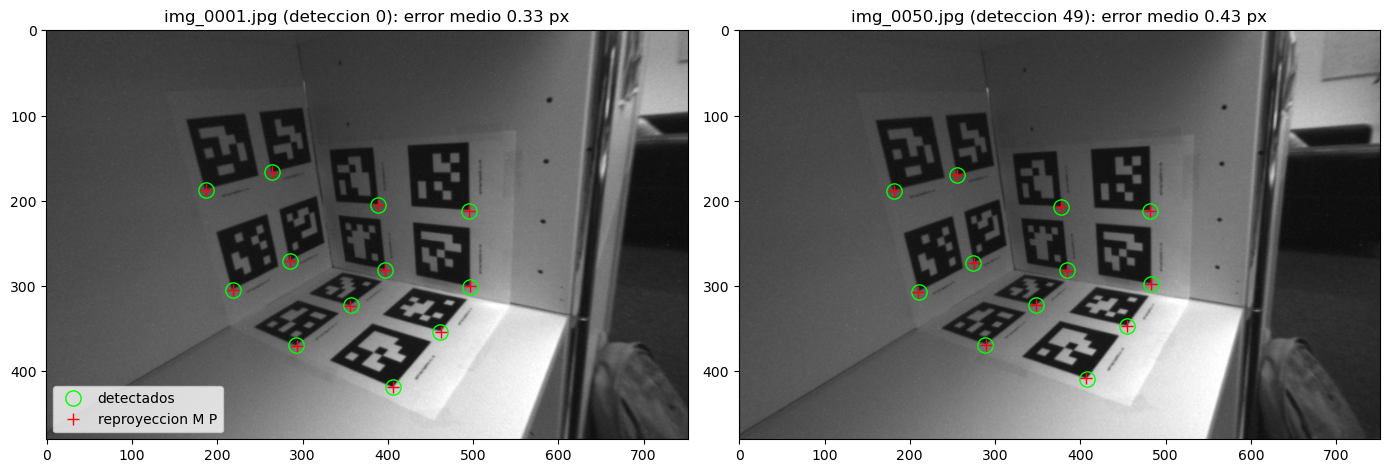

In [3]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from alc import multiplicacionDeMatrices, traspuesta

# --- K estimada con cada una de las 210 detecciones (cada una es un cuadro de video): media y desvio
print("%-18s %s" % ("variante", "alfa_u          alfa_v          gamma         u0            v0           err. reproy. max (media / peor)"))
for nombreVar, alfasIguales, gammaCero in variantes:
    Ks, errs = [], []
    for fila in range(210):
        imgPts = detecciones[fila].reshape(12, 2)
        M = resolverDLT3D(obtenerQ3d(imgPts, objPts))
        R, t, K = devolverMatricesCalibracion3d(M, alfasIguales, gammaCero)
        Ks.append([K[0, 0], K[1, 1], K[0, 1], K[0, 2], K[1, 2]])
        errs.append(verificarCalibracion3d(M, R, t, K, imgPts, objPts)["error_reproyeccion"])
    Ks, errs = np.array(Ks), np.array(errs)
    m = np.mean(Ks, axis=0)
    s = np.sqrt(np.mean((Ks - m) ** 2, axis=0))                 # desvio estandar
    print("%-18s %s   %.2f / %.2f px" % (nombreVar, "  ".join("%6.1f +- %4.1f" % (m[i], s[i]) for i in range(5)),
                                          np.mean(errs), np.max(errs)))

# --- reproyeccion de los 12 puntos con la variante libre, sobre dos cuadros del video
# (la deteccion k corresponde a img_{k+1:04d}.jpg; solo estan las imagenes 1 y 50)
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (fila, archivo) in zip(ejes, [(0, "img_0001.jpg"), (49, "img_0050.jpg")]):
    imgPts = detecciones[fila].reshape(12, 2)
    M = resolverDLT3D(obtenerQ3d(imgPts, objPts))
    P = np.hstack([objPts, np.ones((12, 1))])
    proy = multiplicacionDeMatrices(P, traspuesta(M))
    uv = proy[:, 0:2] / proy[:, 2:3]
    ax.imshow(mpimg.imread(os.path.join(carpeta, archivo)), cmap="gray")
    ax.plot(imgPts[:, 0], imgPts[:, 1], "o", mfc="none", mec="lime", ms=11, label="detectados")
    ax.plot(uv[:, 0], uv[:, 1], "r+", ms=9, label="reproyeccion M P")
    ax.set_title(f"{archivo} (deteccion {fila}): error medio {np.mean(np.sqrt(np.sum((uv - imgPts) ** 2, axis=1))):.2f} px")
ejes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()


**Respuesta 2.**

**Planteo (2.a).** Un punto del mundo $\mathbf P=(U,V,W,1)^T$ se proyecta con $\lambda\,(u,v,1)^T=\mathbf M\mathbf P$, donde $\mathbf M=\mathbf K[\mathbf R\,|\,\mathbf t]\in\mathbb R^{3\times4}$. Si $\mathbf m_1^T,\mathbf m_2^T,\mathbf m_3^T$ son las filas de $\mathbf M$, la tercera da $\lambda=\mathbf m_3^T\mathbf P$ y entonces $u=\frac{\mathbf m_1^T\mathbf P}{\mathbf m_3^T\mathbf P}$, $v=\frac{\mathbf m_2^T\mathbf P}{\mathbf m_3^T\mathbf P}$, es decir

$$(\mathbf m_1^T-u\,\mathbf m_3^T)\mathbf P=0,\qquad(\mathbf m_2^T-v\,\mathbf m_3^T)\mathbf P=0 .$$

Son dos ecuaciones lineales en las 12 entradas de $\mathbf M$ por punto: las filas $[\mathbf P^T,\mathbf 0,-u\mathbf P^T]$ y $[\mathbf 0,\mathbf P^T,-v\mathbf P^T]$ de $Q\in\mathbb R^{24\times12}$ (`obtenerQ3d`), con $Q\mathbf m=0$.

**DLT (2.b).** $\mathbf M$ está definida a menos de escala, así que con ruido se resuelve $\min_{\|\mathbf m\|=1}\|Q\mathbf m\|^2=\min\mathbf m^T(Q^TQ)\mathbf m$: el mínimo se alcanza en el autovector de $Q^TQ$ de menor autovalor (Ej. 1.b), que se ordena por filas en $\mathbf M$ (`resolverDLT3D`).

**Descomposición (2.c).** $\mathbf M=c\,\mathbf K[\mathbf R\,|\,\mathbf t]$ con $c$ desconocida. Si $\mathbf m_1,\mathbf m_2,\mathbf m_3$ son ahora las 3 primeras entradas de cada fila y $\mathbf r_i$ las filas de $\mathbf R$ ($\mathbf K$ triangular superior, $\mathbf R\mathbf R^T=\mathbf I$), se despeja de abajo hacia arriba (Gram-Schmidt). Esto es una **factorización RQ** del bloque izquierdo $c\,\mathbf K\mathbf R$ (triangular superior por ortogonal, el orden inverso de la QR): por eso se arranca por la última fila, que solo depende de $\mathbf r_3$. La hacemos a mano con Gram-Schmidt en lugar de usar una función de biblioteca, y queda única al pedir $\alpha_u,\alpha_v>0$ y $t_3>0$:

1. $\mathbf M\leftarrow\mathbf M/\|\mathbf m_3\|$ (así $\mathbf m_3=\mathbf r_3$) y se elige el signo con $t_3=M_{34}>0$.
2. $\mathbf r_3=\mathbf m_3$.
3. $v_0=\mathbf r_3\cdot\mathbf m_2$, $\;\alpha_v=\|\mathbf m_2-v_0\mathbf r_3\|$, $\;\mathbf r_2=(\mathbf m_2-v_0\mathbf r_3)/\alpha_v$.
4. $u_0=\mathbf r_3\cdot\mathbf m_1$, $\;\gamma=\mathbf r_2\cdot\mathbf m_1$, $\;\alpha_u=\|\mathbf m_1-\gamma\mathbf r_2-u_0\mathbf r_3\|$, $\;\mathbf r_1=(\mathbf m_1-\gamma\mathbf r_2-u_0\mathbf r_3)/\alpha_u$.
5. $\mathbf t$ por sustitución hacia atrás en $\mathbf K\mathbf t=\mathbf M_{[:,4]}$: $t_3=M_{34}$, $t_2=(M_{24}-v_0t_3)/\alpha_v$, $t_1=(M_{14}-\gamma t_2-u_0t_3)/\alpha_u$.

$\mathbf R$ sale ortonormal por construcción (se verifica $\max|\mathbf R\mathbf R^T-\mathbf I|\approx10^{-16}$ y $\det\mathbf R=+1$).

**Por qué es una factorización RQ.** La RQ escribe una matriz cuadrada como triangular superior por ortogonal; acá la triangular es $\mathbf K$ y la ortogonal es la rotación $\mathbf R$ (la "R" de RQ es $\mathbf K$ y la "Q" es $\mathbf R$). Fila por fila, con $\mathbf K$ triangular superior:
$$\mathbf m_3=\mathbf r_3,\qquad \mathbf m_2=\alpha_v\mathbf r_2+v_0\mathbf r_3,\qquad \mathbf m_1=\alpha_u\mathbf r_1+\gamma\mathbf r_2+u_0\mathbf r_3,$$
así que cada fila depende solo de su $\mathbf r_i$ y de las de abajo: es Gram-Schmidt sobre las **filas**, de la última a la primera (la QR hace lo mismo sobre las columnas, de izquierda a derecha).
* $\mathbf K$ (la "R"): triangular superior con diagonal positiva ($\alpha_u,\alpha_v>0$, $K_{33}=1$), invertible ($\det\mathbf K=\alpha_u\alpha_v$); por ser triangular, $\mathbf K\mathbf t=\mathbf m_4$ se resuelve por sustitución hacia atrás (y su inversa también es triangular superior).
* $\mathbf R$ (la "Q"): ortogonal, $\mathbf R\mathbf R^T=\mathbf I$ (filas y columnas ortonormales), $\mathbf R^{-1}=\mathbf R^T$, conserva longitudes y ángulos, número de condición 1; para ser rotación tiene que tener $\det\mathbf R=+1$.
* La RQ existe para toda matriz invertible y es **única** si la diagonal de la triangular es positiva; con $t_3>0$ (la mira delante de la cámara) queda una sola solución con sentido físico.

**Restricciones (2.d, ítems b y c del enunciado).** Se hace primero la descomposición libre y después se fuerza $\gamma=0$ y/o $\alpha_u=\alpha_v=\frac{\alpha_u+\alpha_v}{2}$, recalculando $\mathbf t$ con la $\mathbf K$ modificada. Es una aproximación (la forma exacta sería volver a estimar $\mathbf M$ con la restricción, un problema no lineal), por eso el error de reproyección puede subir.

**Resultados.** Para la detección 0 (variante libre), $\mathbf R=\begin{pmatrix}0{,}618&0{,}129&-0{,}775\\-0{,}355&0{,}926&-0{,}129\\0{,}701&0{,}355&0{,}618\end{pmatrix}$, $\mathbf t\approx(-18{,}2;\,-14{,}5;\,40{,}6)$ y

$$\mathbf K\approx\begin{pmatrix}425{,}9&-0{,}02&354{,}4\\0&424{,}6&256{,}9\\0&0&1\end{pmatrix},$$

con error máximo de reproyección de 0,57 px. Las unidades de $\mathbf t$ son las de los puntos 3D (`p_W_corners.txt` no las indica; por la escala del montaje parecen centímetros, pero no está confirmado).

Como cada detección es un cuadro de un video en el que la cámara se mueve un poco, $\mathbf K$ varía de una a otra (con ruido, la DLT de 12 puntos no la fija mejor que unos pocos píxeles). Para dar un valor único se resume con las 210 detecciones (celda de arriba), media $\pm$ desvío:

| variante | $\alpha_u$ | $\alpha_v$ | $\gamma$ | $u_0$ | $v_0$ | error máx. de reproyección (media / peor) |
|---|---|---|---|---|---|---|
| libre (2.a) | $425{,}9\pm4{,}8$ | $423{,}6\pm4{,}7$ | $-0{,}34\pm1{,}1$ | $357{,}1\pm2{,}4$ | $254{,}0\pm3{,}5$ | 0,84 / 1,36 px |
| $\alpha_u=\alpha_v$ (2.b) | $424{,}7\pm4{,}7$ | $424{,}7\pm4{,}7$ | $-0{,}34\pm1{,}1$ | $357{,}1\pm2{,}4$ | $254{,}0\pm3{,}5$ | 1,41 / 2,50 px |
| $\gamma=0$ (2.c) | $425{,}9\pm4{,}8$ | $423{,}6\pm4{,}7$ | $0$ | $357{,}1\pm2{,}4$ | $254{,}0\pm3{,}5$ | 1,17 / 2,72 px |
| ambas | $424{,}7\pm4{,}7$ | $424{,}7\pm4{,}7$ | $0$ | $357{,}1\pm2{,}4$ | $254{,}0\pm3{,}5$ | 1,58 / 3,89 px |

**Conclusiones.** La cámara es casi ideal: píxeles prácticamente cuadrados ($\alpha_u$ y $\alpha_v$ difieren $\approx0{,}5\,\%$, menos que el desvío entre detecciones) y $\gamma$ estadísticamente nulo. Por eso imponer $\alpha_u=\alpha_v$ o $\gamma=0$ casi no cambia $\mathbf K$ ni $\mathbf R$, y solo sube algo el error máximo de reproyección (en promedio, de 0,84 px a entre 1,2 y 1,6 px), porque la restricción se impone después de ajustar. Sube más cuando la restricción contradice a los datos: en la detección 50, $\gamma$ libre vale $-3{,}2$ y forzar $\gamma=0$ lleva el error de 0,80 a 2,72 px. La figura muestra, para dos cuadros, los puntos detectados y los reproyectados con $\mathbf M$: coinciden a menos de un píxel y medio. Limitaciones: los pocos puntos (12) y que $\mathbf M$ se estime sin normalización de Hartley (el número de condición de $Q$ es $\sim6\cdot10^6$).


### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.


**Respuesta 3 (rango de $Q$).** $Q\in\mathbb{R}^{2n\times 9}$ y $\mathbf{h}$ está definido a menos de escala (8 grados de libertad), así que hace falta $\mathrm{rank}(Q)=8$: así $\dim\ker Q = 9-8=1$ y la solución es única salvo factor de escala. Cada punto aporta 2 ecuaciones, luego $n\ge 4$, y no puede haber 3 puntos colineales (ni en el tablero ni en la imagen). Acá $n=77$, así que $Q$ es de $154\times 9$.

**Cómo se obtienen las esquinas.** La carpeta no trae las coordenadas $(u,v)$, así que se detectan con código propio (`esquinasTablero`, incluida en `alc.py`): las esquinas internas son puntos silla ($\det$ Hessiana de la imagen suavizada muy negativo); se buscan máximos locales con precisión subpíxel y se ordenan armando la grilla y quedándose con el bloque completo de $11\times 7$ centrado.

**Algoritmo.** (1) $\mathbf{H}_j$ por DLT con normalización de Hartley, (2) $A\mathbf{b}=0$ con 2 filas por vista, (3) $B=K^{-T}K^{-1}$ y Cholesky, (4) pose de cada vista con $\mathbf r_1=\lambda K^{-1}\mathbf c_1$, $\mathbf r_2=\lambda K^{-1}\mathbf c_2$, $\mathbf r_3=\mathbf r_1\times\mathbf r_2$, $\mathbf t=\lambda K^{-1}\mathbf c_3$.


In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from alc import (resolverH, armarA, calcularMatrizK2D, obtenerPose2D, esquinasTablero,
                 multiplicacionDeMatrices, traspuesta)

np.set_printoptions(precision=3, suppress=True)

# Puntos del tablero (mm): (U, V) = (30 i, 30 j), i = 0..10, j = 0..6, W = 0.
# Orden k = j*11 + i, igual al de las esquinas detectadas.
objPts = np.array([[30.0 * i, 30.0 * j] for j in range(7) for i in range(11)])

# Carpeta de datos: en el zip del template aparece como " calib" (con un espacio adelante)
nombre = [d for d in os.listdir(".") if d.strip() == "calib"][0]
carpeta = os.path.join(nombre, "coplanar")

# 1) Esquinas (u, v) de cada vista y homografia H_j por DLT (con normalizacion de Hartley)
Hlst = []
imgPtsLst = []
for k in range(1, 21):
    imagen = mpimg.imread(os.path.join(carpeta, f"Im_R_{k}.png"))
    imgPts = esquinasTablero(imagen)                          # 77 x 2
    imgPtsLst.append(imgPts)
    Hlst.append(resolverH(imgPts, objPts))

# 2) K a partir de las 20 homografias
A = armarA(Hlst)                  # 40 x 6
K = calcularMatrizK2D(A)
print("K =\n", K)

# 3) Pose de las vistas 1, 10 y 20 y error de reproyeccion
for k in [1, 10, 20]:
    R, t = obtenerPose2D(Hlst[k - 1], K)
    Rt = np.hstack([R, t.reshape(3, 1)])
    P = np.hstack([objPts, np.zeros((77, 1)), np.ones((77, 1))])   # (U, V, 0, 1)
    proy = multiplicacionDeMatrices(P, traspuesta(multiplicacionDeMatrices(K, Rt)))
    uv = proy[:, 0:2] / proy[:, 2:3]
    err = np.sqrt(np.sum((uv - imgPtsLst[k - 1]) ** 2, axis=1))
    print(f"\nIm_R_{k}: R =\n{R}\n t (mm) = {t}\n error de reproyeccion: medio {np.mean(err):.2f} px, max {np.max(err):.2f} px")


K =
 [[743.729  -1.001 519.083]
 [  0.    755.092 298.882]
 [  0.      0.      1.   ]]

Im_R_1: R =
[[ 1.    -0.012 -0.028]
 [ 0.012  1.     0.008]
 [ 0.028 -0.008  1.   ]]
 t (mm) = [-108.314 -141.502  549.25 ]
 error de reproyeccion: medio 0.18 px, max 0.43 px

Im_R_10: R =
[[ 0.997  0.068 -0.024]
 [-0.063  0.986  0.157]
 [ 0.035 -0.155  0.987]]
 t (mm) = [ -95.529 -154.18   540.185]
 error de reproyeccion: medio 0.14 px, max 0.43 px

Im_R_20: R =
[[ 0.99   0.027 -0.139]
 [-0.039  0.996 -0.084]
 [ 0.136  0.088  0.987]]
 t (mm) = [ -82.98  -146.551  488.437]
 error de reproyeccion: medio 0.17 px, max 0.34 px


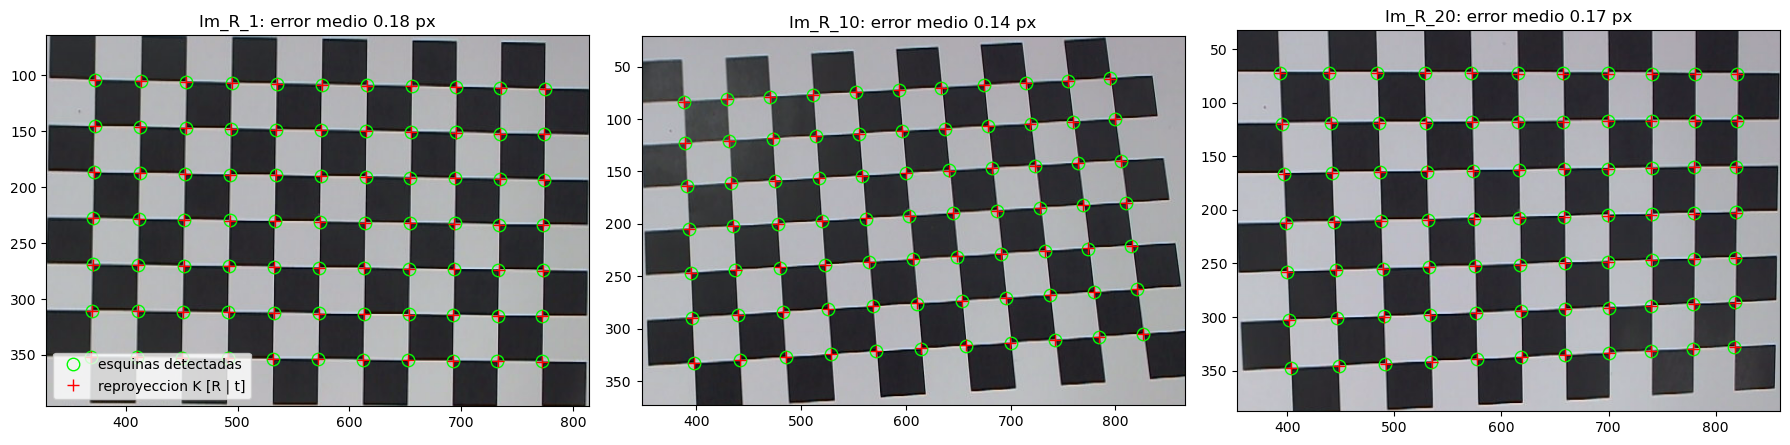

In [5]:
# Esquinas detectadas y reproyeccion con la pose estimada, para las 3 vistas pedidas
P = np.hstack([objPts, np.zeros((77, 1)), np.ones((77, 1))])          # (U, V, 0, 1)
fig, ejes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, k in zip(ejes, [1, 10, 20]):
    R, t = obtenerPose2D(Hlst[k - 1], K)
    proy = multiplicacionDeMatrices(P, traspuesta(multiplicacionDeMatrices(K, np.hstack([R, t.reshape(3, 1)]))))
    uv = proy[:, 0:2] / proy[:, 2:3]
    det = imgPtsLst[k - 1]
    ax.imshow(mpimg.imread(os.path.join(carpeta, f"Im_R_{k}.png")), cmap="gray")
    ax.plot(det[:, 0], det[:, 1], "o", mfc="none", mec="lime", ms=9, label="esquinas detectadas")
    ax.plot(uv[:, 0], uv[:, 1], "r+", ms=8, label="reproyeccion K [R | t]")
    ax.set_xlim(det[:, 0].min() - 40, det[:, 0].max() + 40)
    ax.set_ylim(det[:, 1].max() + 40, det[:, 1].min() - 40)
    ax.set_title(f"Im_R_{k}: error medio {np.mean(np.sqrt(np.sum((uv - det) ** 2, axis=1))):.2f} px")
ejes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()


**Respuesta 3.a (matriz $\mathbf K$).** Para cada una de las 20 vistas se detectan las 77 esquinas internas y se estima la homografía $\mathbf H_j$ del tablero a la imagen ($\lambda\,(u,v,1)^T=\mathbf H_j\,(U,V,1)^T$, con $W=0$ y $\mathbf H_j=\mathbf K[\mathbf r_1\ \mathbf r_2\ \mathbf t]$ a menos de escala). Cada vista aporta dos restricciones sobre $\mathbf B=\mathbf K^{-T}\mathbf K^{-1}$, que viene de $\mathbf r_1^T\mathbf r_2=0$ y $\|\mathbf r_1\|=\|\mathbf r_2\|$:

$$\mathbf h_1^T\mathbf B\,\mathbf h_2=0,\qquad \mathbf h_1^T\mathbf B\,\mathbf h_1-\mathbf h_2^T\mathbf B\,\mathbf h_2=0 .$$

Con $\mathbf b=(B_{11},B_{12},B_{22},B_{13},B_{23},B_{33})^T$ se escriben como $\mathbf v_{12}^T\mathbf b=0$ y $(\mathbf v_{11}-\mathbf v_{22})^T\mathbf b=0$, y las 20 vistas dan $A\mathbf b=0$ con $A\in\mathbb R^{40\times6}$ (`armarA`). $\mathbf b$ es el autovector de $A^TA$ de menor autovalor; con $\mathbf B=\mathbf L\mathbf L^T$ (Cholesky) resulta $\mathbf K=(\mathbf L^T)^{-1}$ normalizada con $K_{33}=1$ (`calcularMatrizK2D`). El resultado es

$$\mathbf K\approx\begin{pmatrix}743{,}7&-1{,}0&519{,}1\\0&755{,}1&298{,}9\\0&0&1\end{pmatrix}.$$

Es plausible: $\alpha_u\approx744$ y $\alpha_v\approx755$ difieren solo un 1,5 % (píxeles casi cuadrados), $\gamma\approx-1$ es prácticamente 0 (ejes del sensor perpendiculares) y el punto principal $(519;\,299)$ queda cerca del centro de la imagen.

**Respuesta 3.b (poses).** Con $\mathbf K$ conocida, cada vista da $\lambda=1/\|\mathbf K^{-1}\mathbf h_1\|$, $\mathbf r_1=\lambda\mathbf K^{-1}\mathbf h_1$, $\mathbf r_2=\lambda\mathbf K^{-1}\mathbf h_2$, $\mathbf r_3=\mathbf r_1\times\mathbf r_2$ y $\mathbf t=\lambda\mathbf K^{-1}\mathbf h_3$ (el signo de $\lambda$ se elige con $t_3>0$, tablero delante de la cámara). Como el ruido hace que $[\mathbf r_1\,\mathbf r_2\,\mathbf r_3]$ no sea exactamente una rotación, se la proyecta a la rotación más cercana (`obtenerPose2D`). Resultados ($\mathbf t$ en mm):

| vista | $\mathbf t$ (mm) | distancia $t_3$ | error de reproyección (media / máx.) |
|---|---|---|---|
| `Im_R_1` | $(-108{,}3;\,-141{,}5;\,549{,}3)$ | ≈ 0,55 m | 0,18 / 0,43 px |
| `Im_R_10` | $(-95{,}5;\,-154{,}2;\,540{,}2)$ | ≈ 0,54 m | 0,14 / 0,43 px |
| `Im_R_20` | $(-83{,}0;\,-146{,}6;\,488{,}4)$ | ≈ 0,49 m | 0,17 / 0,34 px |

`Im_R_1` es casi frontal ($\mathbf R\approx\mathbf I$, la normal del tablero forma $\arccos R_{33}\approx1{,}6^\circ$ con el eje óptico); en `Im_R_10` y `Im_R_20` el tablero está inclinado unos $9{,}2^\circ$ y $9{,}3^\circ$ respecto del plano de la imagen. Las tres $\mathbf R$ son ortonormales con $\det=+1$. La figura muestra las esquinas detectadas (círculos verdes) y las reproyectadas con $\mathbf K[\mathbf R\,|\,\mathbf t]$ (cruces rojas): coinciden a menos de medio píxel, lo que valida a la vez el detector de esquinas, el orden de los puntos, $\mathbf K$ y las poses.


In [ ]:
# --- Comparacion: K y poses calculadas con distinta cantidad de puntos por vista ---
# Se usan las esquinas ya detectadas (imgPtsLst) y se estima cada H_j solo con un subconjunto.
# El error de reproyeccion se mide siempre sobre las 77 esquinas, para comparar en igualdad.
def indices(pares):
    """Indices k = j*11 + i de las esquinas (i, j) del tablero."""
    return [j * 11 + i for i, j in pares]

subconjuntos = [
    ("4 puntos (minimo: esquinas del tablero)", indices([(0, 0), (10, 0), (0, 6), (10, 6)])),
    ("20 puntos (grilla de 5 x 4)",              indices([(i, j) for j in (0, 2, 4, 6) for i in (0, 2, 5, 8, 10)])),
    ("77 puntos (todos)",                        list(range(77))),
]
P77 = np.hstack([objPts, np.zeros((77, 1)), np.ones((77, 1))])          # (U, V, 0, 1)
for nombreSub, s in subconjuntos:
    Hs = [resolverH(imgPtsLst[k][s], objPts[s]) for k in range(20)]
    Ks = calcularMatrizK2D(armarA(Hs))
    errores, lineasPose = [], []
    for k in range(20):
        R, t = obtenerPose2D(Hs[k], Ks)
        proy = multiplicacionDeMatrices(P77, traspuesta(multiplicacionDeMatrices(Ks, np.hstack([R, t.reshape(3, 1)]))))
        uv = proy[:, 0:2] / proy[:, 2:3]
        e = np.sqrt(np.sum((uv - imgPtsLst[k]) ** 2, axis=1))
        errores.append(e)
        if k + 1 in (1, 10, 20):
            lineasPose.append(f"   Im_R_{k + 1}: t (mm) = {t}, error en las 77 esquinas: medio {np.mean(e):.2f} px, max {np.max(e):.2f} px")
    errores = np.concatenate(errores)
    print(f"{nombreSub}: alfa_u = {Ks[0, 0]:.1f}, alfa_v = {Ks[1, 1]:.1f}, gamma = {Ks[0, 1]:.2f}, "
          f"u0 = {Ks[0, 2]:.1f}, v0 = {Ks[1, 2]:.1f}")
    print(f"   error de reproyeccion en las 77 esquinas de las 20 vistas: medio {np.mean(errores):.2f} px, max {np.max(errores):.2f} px")
    print("\n".join(lineasPose) + "\n")

**Comparación según la cantidad de puntos.** Se repitió el cálculo estimando cada $\mathbf H_j$ con distinta cantidad de esquinas por vista (las 20 vistas siempre se usan para $\mathbf K$). El error de reproyección se mide siempre sobre las 77 esquinas de las 20 vistas, también las que no se usaron para calcular.

* **4 puntos:** es el mínimo aceptable, porque hace falta $\mathrm{rank}(Q)=8$ y cada punto aporta 2 ecuaciones. Se eligieron las 4 esquinas extremas del tablero (ningún trío colineal y la mayor separación posible). Con 4 puntos el sistema queda exactamente determinado: $\mathbf H_j$ pasa justo por esos 4 puntos y no promedia el ruido.
* **20 puntos:** cantidad intermedia arbitraria, una grilla de $5\times4$ repartida por todo el tablero ($i\in\{0,2,5,8,10\}$, $j\in\{0,2,4,6\}$).
* **77 puntos:** todas las esquinas (el cálculo de 3.a y 3.b).

| puntos por vista | $\alpha_u$ | $\alpha_v$ | $\gamma$ | $u_0$ | $v_0$ | reproyección en las 77 esquinas (media / máx.) |
|---|---|---|---|---|---|---|
| 4 | 743,0 | 754,9 | −1,13 | 519,7 | 296,2 | 0,27 / 1,04 px |
| 20 | 746,7 | 758,1 | −1,07 | 518,6 | 299,0 | 0,21 / 0,87 px |
| 77 | 743,7 | 755,1 | −1,00 | 519,1 | 298,9 | 0,20 / 0,84 px |

| vista | $\mathbf t$ con 4 puntos (mm) | con 20 | con 77 |
|---|---|---|---|
| `Im_R_1` | $(-108{,}7;\,-139{,}6;\,548{,}6)$ | $(-108{,}0;\,-141{,}5;\,551{,}2)$ | $(-108{,}3;\,-141{,}5;\,549{,}2)$ |
| `Im_R_10` | $(-96{,}2;\,-152{,}5;\,540{,}8)$ | $(-95{,}2;\,-154{,}3;\,542{,}3)$ | $(-95{,}5;\,-154{,}2;\,540{,}2)$ |
| `Im_R_20` | $(-83{,}2;\,-144{,}6;\,487{,}6)$ | $(-82{,}7;\,-146{,}5;\,490{,}1)$ | $(-83{,}0;\,-146{,}6;\,488{,}4)$ |

Las tres versiones dan prácticamente la misma $\mathbf K$ (diferencias de menos de 0,5 % en las focales y de unos 3 px en el punto principal) y poses que difieren en 1 a 3 mm. Al aumentar los puntos baja el error en las esquinas no usadas: de 0,27 px de media con 4 puntos a 0,20 px con 77. Con 4 puntos, las vistas peor resueltas llegan a 1 px (en `Im_R_10`, 0,46 px de media contra 0,14 px con 77). Pasar de 20 a 77 casi no mejora: con 20 puntos bien repartidos el ruido ya está promediado.

El resultado con 4 puntos es bueno porque son los más separados. La cantidad no alcanza sola, también importa dónde están los puntos: con 4 esquinas vecinas en el centro del tablero (un cuadrado de 30 mm de lado), el sistema sigue teniendo rango 8, pero queda mal condicionado. Ahí $\mathbf K$ sale muy distinta ($\alpha_u\approx912$, $\gamma\approx-21$, $u_0\approx723$) y el error en las 77 esquinas llega a 4 px de media y 23 px de máximo. Con más puntos repartidos por todo el tablero, el resultado depende menos de esa elección.

**Por qué la rotación se ortogonaliza con Newton y no con la SVD.** Por el ruido, $\mathbf Q=[\mathbf r_1\ \mathbf r_2\ \mathbf r_3]$ no es exactamente una rotación, y Zhang (en su paper "A exible new technique for camera calibration") propone reemplazarla por la rotación más cercana, $\mathbf R=\mathbf U\mathbf V^T$, con $\mathbf Q=\mathbf U\boldsymbol\Sigma\mathbf V^T$ (SVD). En `obtenerPose2D` calculamos esa misma matriz $\mathbf U\mathbf V^T$ (el factor ortogonal de la descomposición polar de $\mathbf Q$) con la iteración de Newton $\mathbf R_{k+1}=\tfrac12\big(\mathbf R_k+\mathbf R_k^{-T}\big)$, partiendo de $\mathbf R_0=\mathbf Q$. El motivo es numérico: como $\mathbf Q$ ya es casi una rotación, sus tres valores singulares son casi iguales (por ejemplo $1{,}00024$, $1{,}00021$ y $0{,}99997$ en `Im_R_10`). En ese caso los vectores singulares, que nuestra `svd_reducida` obtiene como autovectores de $\mathbf Q^T\mathbf Q$, quedan mal determinados, porque autovalores casi repetidos hacen que sus autovectores estén mal condicionados. Con esa SVD, la $\mathbf R$ resultante salía ortonormal solo hasta $\max|\mathbf R^T\mathbf R-\mathbf I|\approx10^{-4}$. Newton, en cambio, nunca separa $\mathbf U$ y $\mathbf V$: obtiene directamente el producto $\mathbf U\mathbf V^T$, que sí está bien condicionado. Solo necesita invertir una matriz $3\times3$ casi ortogonal (número de condición $\approx1$), converge cuadráticamente en 2 o 3 pasos y deja $\mathbf R$ ortonormal a precisión de máquina ($\approx10^{-16}$), con $\det\mathbf R=+1$.

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

Error de reproyeccion de los 6 puntos de referencia (px): [1.292 0.629 2.098 1.245 0.996 0.791]
a) Enzo: U = 22.2 m (distancia a la linea de gol), V = 39.7 m


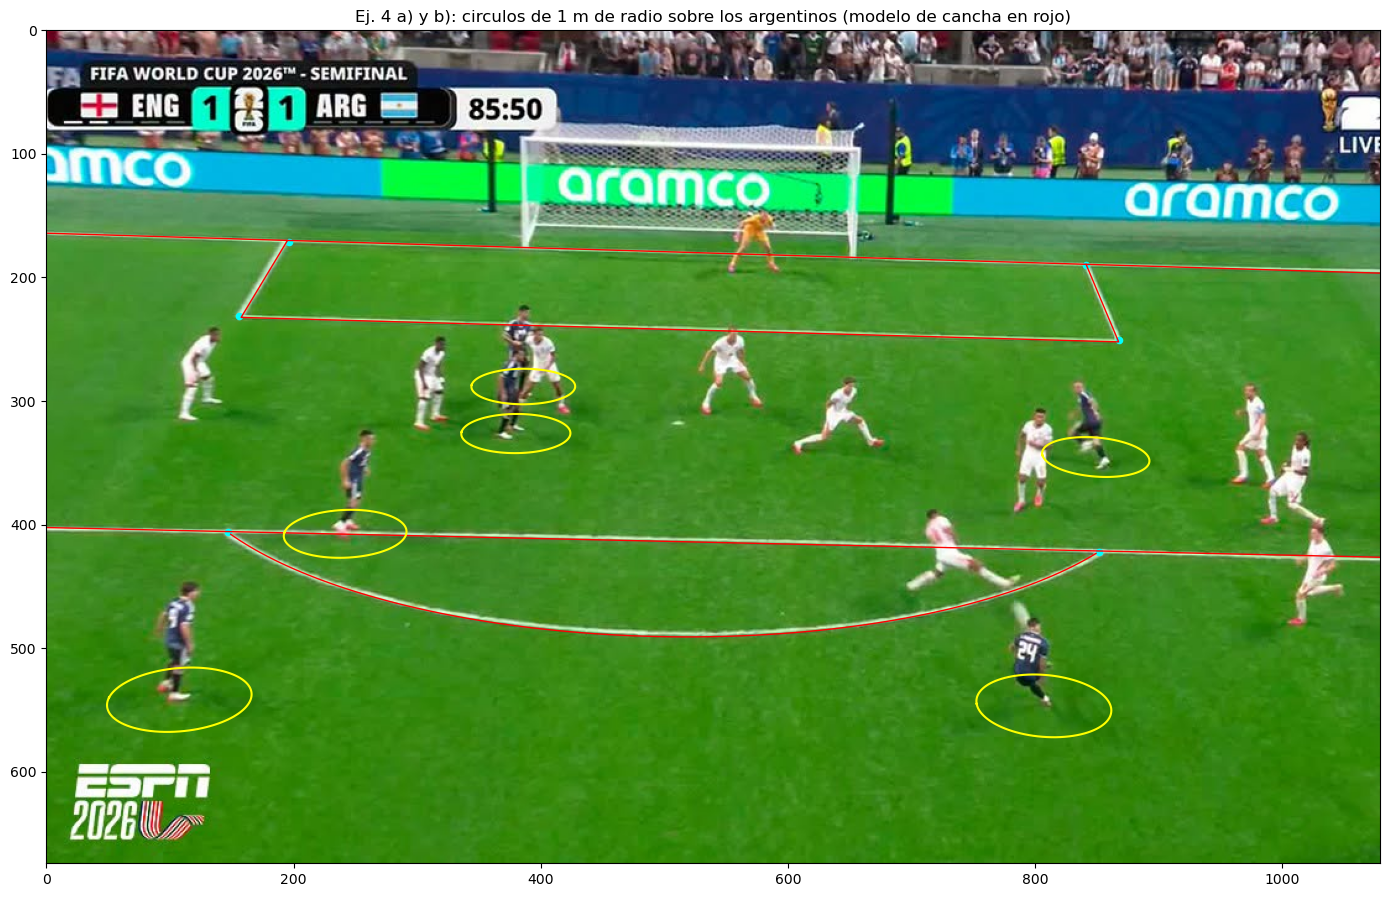

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from alc import resolverH, inversa, proyectarPuntos, circuloEnPlano

# Fotos (carpeta futbol del template)
fotoGol = os.path.join("futbol", "test-gol-enzo.png")
fotoOffside = os.path.join("futbol", "test-fuera-de-juego.png")

# Sistema de la cancha (esquema estadio_azteca.png, 105 x 68 m): U = distancia a la
# linea de gol del arco que se ataca (U = 0 en esa linea), V = posicion a lo ancho
# (0 a 68; el centro del arco esta en V = 34). Medidas reglamentarias:
semiAreaChica = 18.32 / 2                   # el area chica es de 5,5 x 18,32 m
profAreaChica = 5.5
profAreaGrande = 16.5                       # el area grande es de 16,5 x 40,32 m
semiAreaGrande = 40.32 / 2
radioArco = 9.15                            # arco del area, centrado en el punto penal (11 m)
mitadCuerda = np.sqrt(radioArco ** 2 - (profAreaGrande - 11.0) ** 2)   # arco con la linea del area grande: V = 34 +- 7,31

# ---------------------------------------------------------------- a) y b): gol-enzo
# 6 correspondencias (pixel de la foto -> metros de la cancha). Los pixeles se leyeron en
# recortes ampliados de la foto. Izquierda de la foto = V chico (la eleccion es arbitraria;
# solo hay que ser consistente).
pxGol = np.array([[196, 171], [841, 190],      # area chica, esquinas sobre la linea de gol
                  [156, 231], [868, 251],      # area chica, esquinas del frente
                  [147, 406], [852, 422]],     # arco del area grande con la linea del area grande
                 dtype=float)
cancha = np.array([[0.0, 34 - semiAreaChica], [0.0, 34 + semiAreaChica],
                   [profAreaChica, 34 - semiAreaChica], [profAreaChica, 34 + semiAreaChica],
                   [profAreaGrande, 34 - mitadCuerda], [profAreaGrande, 34 + mitadCuerda]])

H = resolverH(pxGol, cancha)         # cancha (metros) -> foto (pixeles)
Hinv = inversa(H)                    # foto (pixeles) -> cancha (metros)
errores = np.sqrt(np.sum((proyectarPuntos(H, cancha) - pxGol) ** 2, axis=1))
print("Error de reproyeccion de los 6 puntos de referencia (px):", errores)

# a) Distancia de Enzo (#24) a la linea de gol: pie de apoyo en la foto -> cancha con H^-1.
pieEnzo = np.array([807.0, 546.0])
U_enzo, V_enzo = proyectarPuntos(Hinv, pieEnzo)[0]
print(f"a) Enzo: U = {U_enzo:.1f} m (distancia a la linea de gol), V = {V_enzo:.1f} m")

# b) Jugadores argentinos (camiseta oscura): pie en la foto (px). El de "oculto" esta tapado
# por otros jugadores: su pie es una estimacion.
argentinos = {"Enzo": pieEnzo,
              "izquierda": np.array([108.0, 541.0]),
              "centro-izq": np.array([242.0, 407.0]),
              "centro-der": np.array([380.0, 326.0]),
              "oculto (estimado)": np.array([386.0, 288.0]),
              "derecha": np.array([849.0, 345.0])}

def lineasModelo(H, color, ax):
    """Dibuja sobre la foto las lineas de la cancha (area chica, area grande, arco, linea de gol)."""
    segmentos = [[[0, 0], [0, 68]],
                 [[0, 34 - semiAreaGrande], [profAreaGrande, 34 - semiAreaGrande],
                  [profAreaGrande, 34 + semiAreaGrande], [0, 34 + semiAreaGrande]],
                 [[0, 34 - semiAreaChica], [profAreaChica, 34 - semiAreaChica],
                  [profAreaChica, 34 + semiAreaChica], [0, 34 + semiAreaChica]]]
    for seg in segmentos:
        q = proyectarPuntos(H, np.array(seg, dtype=float))
        ax.plot(q[:, 0], q[:, 1], color=color, lw=1)
    arco = circuloEnPlano((11.0, 34.0), radioArco, 200)
    arco = arco[arco[:, 0] >= profAreaGrande]          # solo la parte fuera del area
    q = proyectarPuntos(H, arco)
    ax.plot(q[:, 0], q[:, 1], color=color, lw=1)

imagen = mpimg.imread(fotoGol)
fig, ax = plt.subplots(figsize=(14, 9))
ax.imshow(imagen[:, :, 0:3])
lineasModelo(H, "red", ax)                       # chequeo visual: el modelo cae sobre las lineas reales
ax.scatter(pxGol[:, 0], pxGol[:, 1], c="cyan", s=20)
for nombre, pie in argentinos.items():
    centro = proyectarPuntos(Hinv, pie)[0]                       # pie -> cancha
    circulo = circuloEnPlano(centro, 1.0, 60)                    # circulo de 1 m de radio en la cancha
    q = proyectarPuntos(H, circulo)                              # cancha -> foto
    ax.plot(q[:, 0], q[:, 1], color="yellow", lw=1.5)
ax.set_xlim(0, imagen.shape[1])
ax.set_ylim(imagen.shape[0], 0)
ax.set_title("Ej. 4 a) y b): circulos de 1 m de radio sobre los argentinos (modelo de cancha en rojo)")
plt.tight_layout()
plt.show()


**Numeración.** Las respuestas siguen la del enunciado del PDF: **4.a** distancia de Enzo a la línea de gol, **4.b** círculos sobre los argentinos y **4.c** fuera de juego (las celdas de arriba, del template, agrupan los dos primeros en un solo inciso). En 4.b el PDF pide un círculo de **1 metro de radio**, mientras que el texto del template dice "diámetro": usamos el radio, que es lo que pide el PDF.

**Método (4.a y 4.b).** El piso es un plano, así que la foto y la cancha se relacionan por una homografía $\lambda\,(u,v,1)^T=\mathbf H\,(U,V,1)^T$. Con 6 correspondencias (esquinas del área chica y extremos del arco del área grande, cuyas coordenadas salen de las medidas reglamentarias de `estadio_azteca.png`) se arma el sistema $Q\mathbf h=\mathbf 0$ de la ecuación 11 y se resuelve con `resolverH` (DLT con normalización de Hartley). Para medir se usa $\mathbf H^{-1}$ (pixel → metros) y para dibujar $\mathbf H$ (metros → pixel); en ambos casos se divide por la tercera coordenada.

**Chequeos.** El error de reproyección de los 6 puntos es de 0,6 a 2,1 px, y el modelo de cancha dibujado en rojo cae sobre las líneas reales de la foto. Además, el punto del arco $(U,V)=(20{,}15;\,34)$, que no se usó para ajustar $\mathbf H$, cae sobre la línea blanca de la foto, a ≤ 3 px (verificado aparte; ese chequeo no forma parte de la entrega).

**Respuesta 4.a.** Enzo (#24) estaba a **≈ 22 m** de la línea de gol ($U=22{,}2$ m, $V=39{,}7$ m) cuando pateó. Si se perturban 1 px las referencias y 3 px el pie, el resultado varía unos ±0,1 m. A eso se suma el error del modelo: el arco del área, que no se usó para ajustar $\mathbf H$ salvo en sus extremos, queda hasta 3 px (≈ 0,2 m) corrido en el medio, porque una homografía no modela la distorsión de la lente, y Enzo está más allá del arco. Elegir otro punto de contacto del pie con el piso suma otros ~0,5 m, así que conviene dar "unos 22 m".

**Respuesta 4.b.** Los 6 jugadores de camiseta oscura quedan marcados con un círculo de 1 m de radio sobre el piso (se ven como elipses por la perspectiva). Un jugador queda tapado por otros, justo delante del área chica (pie estimado en el píxel (386, 288)): su círculo es una estimación.


Error de reproyeccion de los 6 puntos de referencia (px): [0.254 0.65  1.513 0.537 1.103 0.563]
Ultimo defensor: naranja 1 (pie der.), U0 = 14.39 m  (linea de offside: U = 14.39)
blanco 1: U = 15.15 m -> detras de la linea (-0.75 m)
blanco 2: U = 15.42 m -> detras de la linea (-1.02 m)
blanco 3 (#24): U = 14.52 m -> detras de la linea (-0.13 m)
blanco 4 (#5): U = 13.91 m -> ADELANTE de la linea (+0.49 m)


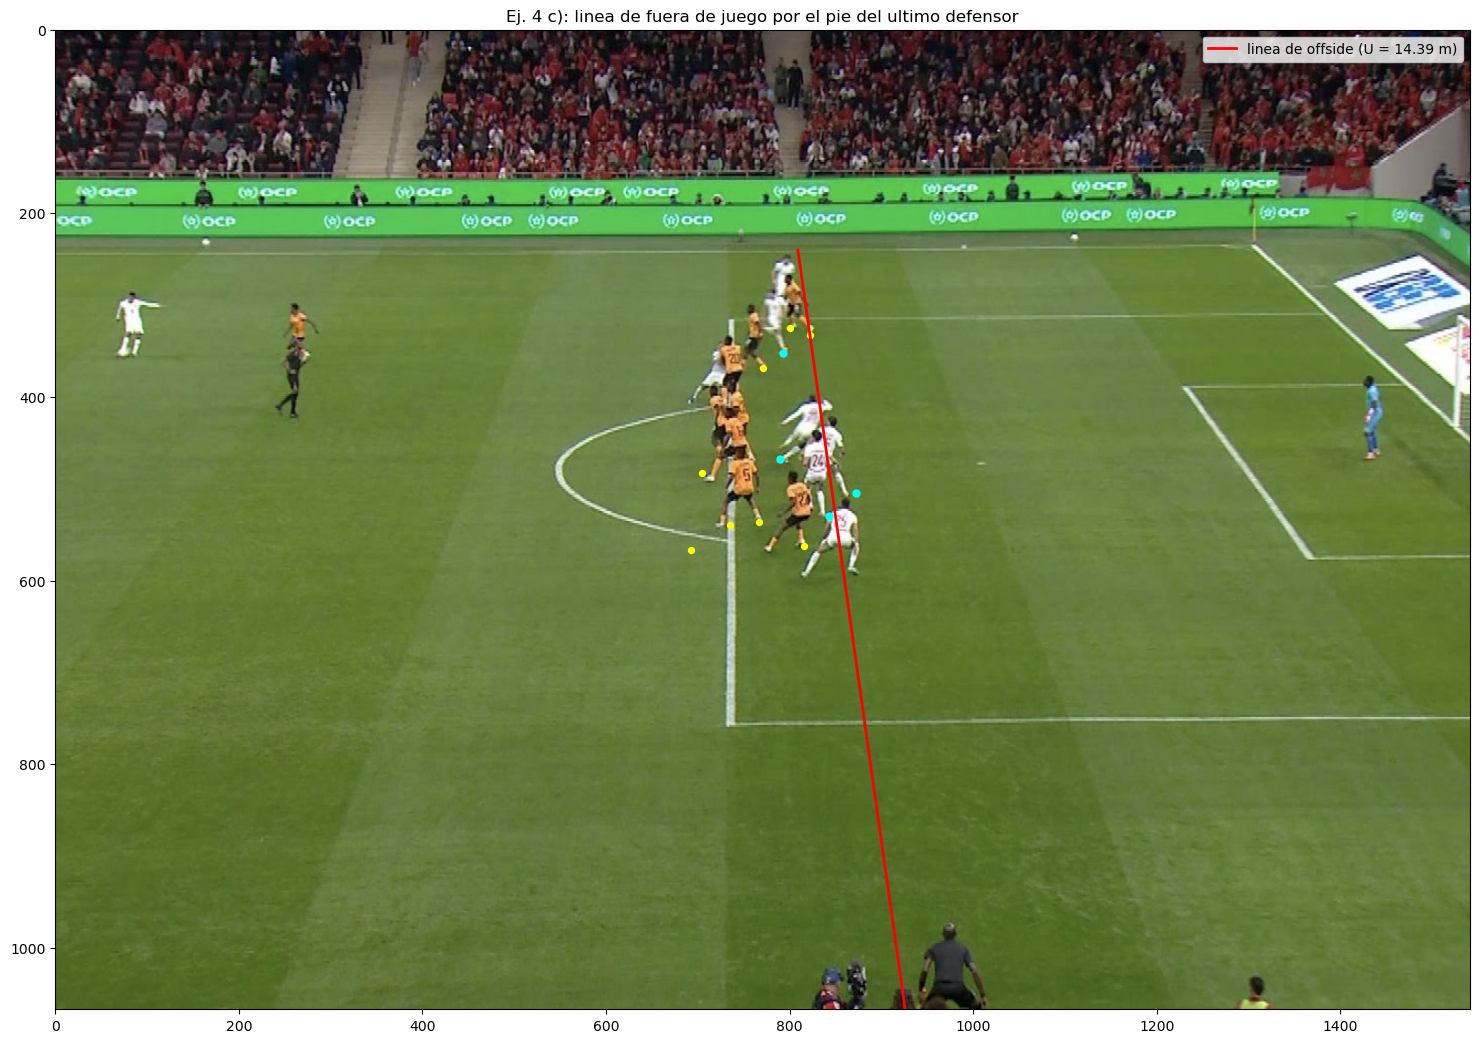

In [7]:
# ---------------------------------------------------------------- c) posible offside
# Esta foto mira al arco desde un costado: V crece hacia la camara y U hacia el centro de
# la cancha. 6 correspondencias: esquinas de las dos areas, extremo del arco y la esquina
# de la cancha (base de la bandera).
pxOff = np.array([[736, 316], [735, 757],        # area grande, esquinas del frente
                  [1230, 391], [1368, 576],      # area chica, esquinas del frente
                  [736, 557],                    # arco del area grande con la linea del area grande
                  [1305, 236]], dtype=float)     # esquina de la cancha (U = 0, V = 0)
canchaOff = np.array([[profAreaGrande, 34 - semiAreaGrande], [profAreaGrande, 34 + semiAreaGrande],
                      [profAreaChica, 34 - semiAreaChica], [profAreaChica, 34 + semiAreaChica],
                      [profAreaGrande, 34 + mitadCuerda],
                      [0.0, 0.0]])
H2 = resolverH(pxOff, canchaOff)
H2inv = inversa(H2)
errores2 = np.sqrt(np.sum((proyectarPuntos(H2, canchaOff) - pxOff) ** 2, axis=1))
print("Error de reproyeccion de los 6 puntos de referencia (px):", errores2)

# Pies (px) de los defensores (naranja) y de los atacantes (blanco) que importan.
defensores = {"naranja 1 (pie der.)": (822, 332), "naranja 1 (pie izq.)": (800, 325),
              "naranja 2": (771, 368), "naranja 3 (pie izq.)": (735, 540),
              "naranja 3 (pie der.)": (767, 536), "naranja 4 (pie izq.)": (693, 567),
              "naranja 4 (pie der.)": (816, 562), "naranja 5": (705, 483)}
atacantes = {"blanco 1": (793, 352), "blanco 2": (790, 468),
             "blanco 3 (#24)": (843, 530), "blanco 4 (#5)": (872, 505)}

# Ultimo defensor de campo (el arquero, de celeste, es el ultimo): el de menor U.
Udef = {k: proyectarPuntos(H2inv, np.array(v, dtype=float))[0][0] for k, v in defensores.items()}
ultimo = min(Udef, key=Udef.get)
U0 = Udef[ultimo]
print(f"Ultimo defensor: {ultimo}, U0 = {U0:.2f} m  (linea de offside: U = {U0:.2f})")
for nombre, pie in atacantes.items():
    U, V = proyectarPuntos(H2inv, np.array(pie, dtype=float))[0]
    print(f"{nombre}: U = {U:.2f} m -> {'ADELANTE de la linea' if U < U0 else 'detras de la linea'} "
          f"({U0 - U:+.2f} m)")

imagen2 = mpimg.imread(fotoOffside)
fig, ax = plt.subplots(figsize=(15, 10.5))
ax.imshow(imagen2[:, :, 0:3])
linea = proyectarPuntos(H2, np.array([[U0, 0.0], [U0, 68.0]]))   # recta paralela a la linea de fondo
ax.plot(linea[:, 0], linea[:, 1], color="red", lw=2, label=f"linea de offside (U = {U0:.2f} m)")
for pie in atacantes.values():
    ax.scatter(pie[0], pie[1], c="cyan", s=25)
for pie in defensores.values():
    ax.scatter(pie[0], pie[1], c="yellow", s=18)
ax.set_xlim(0, imagen2.shape[1])
ax.set_ylim(imagen2.shape[0], 0)
ax.legend()
ax.set_title("Ej. 4 c): linea de fuera de juego por el pie del ultimo defensor")
plt.tight_layout()
plt.show()


**Respuesta 4.c.** Con 6 correspondencias (esquinas del área grande y chica, extremo del arco y esquina de la cancha) se estima la $\mathbf H$ de esta foto (error de reproyección de 0,3 a 1,5 px). El arquero (de celeste) es el último adversario, así que el "último defensor" es el jugador naranja de menor $U$: su pie adelantado marca la línea de fuera de juego en $U_0\approx 14{,}4$ m. La recta $U=U_0$ es paralela a la línea de fondo y se proyecta a la foto con $\mathbf H$ (en rojo).

Atacantes (pies): el blanco **#5** queda **≈ 0,5 m más adelantado** que la línea ($U\approx13{,}9$ m, ventaja $0{,}48\pm0{,}10$ m al perturbar los píxeles), por lo que estaba en posición de **fuera de juego**. El #24 queda unos 0,1 m detrás de la línea (dentro del error), y los otros dos blancos están claramente detrás.

**Limitaciones.** La homografía vale solo para puntos del piso: se usaron los pies. En el reglamento cuentan también la cabeza y el cuerpo (no los brazos), que no están en el plano del piso, así que el resultado es una aproximación. La incertidumbre de 0,1 m es solo por error de marcado de pixeles; la elección del punto de contacto del pie suma más.


### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

In [8]:
import os
import numpy as np
from alc import resolverH, calcularKRestringida, proyectarPuntos

np.set_printoptions(precision=3, suppress=True)

# 5 puntos del mundo (X, Y, Z) y su pixel (u_k, v_k) en 4 vistas
datos = np.loadtxt(os.path.join("salguero", "world_img_pts.csv"), delimiter=";", skiprows=1)
mundo = datos[:, 1:3]          # se ignora Z (los puntos del cordon estan a 0,1 m)
centro = (800.0, 600.0)        # supuesto: punto principal en el centro de la imagen de 1600 x 1200

# una homografia por vista, con Z = 0 para todos los puntos
Hlst = []
for k in range(4):
    pix = datos[:, 4 + 2 * k: 6 + 2 * k]
    H = resolverH(pix, mundo)
    Hlst.append(H)
    err = proyectarPuntos(H, mundo) - pix
    print("vista", k, "- error de reproyeccion de H por punto (px):",
          np.sqrt(err[:, 0] ** 2 + err[:, 1] ** 2))

# f con las 4 vistas juntas (gamma = 0, pixeles cuadrados, centro fijo)
K, residuo = calcularKRestringida(Hlst, centro)
print("\nK =\n", K)
print("residuo relativo de las ecuaciones:", residuo)

# dispersion: f estimada con cada vista por separado
print("f por vista:", [round(calcularKRestringida([H], centro)[0][0, 0]) for H in Hlst])


vista 0 - error de reproyeccion de H por punto (px): [10.2    2.993  2.51   8.478  0.574]
vista 1 - error de reproyeccion de H por punto (px): [13.291  4.005  3.373 11.137  0.762]
vista 2 - error de reproyeccion de H por punto (px): [10.585  4.307  3.707  9.052  0.625]
vista 3 - error de reproyeccion de H por punto (px): [10.622  3.781  3.276  9.01   0.622]

K =
 [[3497.266    0.     800.   ]
 [   0.    3497.266  600.   ]
 [   0.       0.       1.   ]]
residuo relativo de las ecuaciones: 0.35100946015032586
f por vista: [3028, 4040, 3159, 3235]


**Respuesta 5.a.**

**Método.** No se usa la calibración con puntos 3D (DLT del Ej. 2) porque cada vista tiene solo 5 puntos: dan 10 ecuaciones, y para que $Q$ tenga rango 11 hacen falta al menos 6 puntos no coplanares. Además, los puntos son casi coplanares (sus $Z$ difieren solo 0,1 m), lo que dejaría a $Q$ muy mal condicionada. Se aplica el algoritmo de Zhang (Ej. 3) tomando $Z=0$ para los 5 puntos: se calcula una homografía $\mathbf H_k$ por vista con `resolverH` y se arma el sistema $A\mathbf b=0$ con `armarA`. Los puntos del cordón están en realidad a $Z=0{,}1$ m, así que esto introduce un error sistemático que tratamos como ruido, por lo cual calibrar en 2D es una aproximación. El error de reproyección de cada $\mathbf H_k$ es de 0,6 a 13 px según el punto.

**Medición del error de reproyección.** Para cada vista $k$ se proyecta cada punto del mundo con su homografía, $\lambda\,(\hat u_i,\hat v_i,1)^T=\mathbf H_k\,(X_i,Y_i,1)^T$ (es decir, $\hat u_i=(\mathbf H_kP_i)_1/(\mathbf H_kP_i)_3$ y $\hat v_i=(\mathbf H_kP_i)_2/(\mathbf H_kP_i)_3$), y se mide la distancia en píxeles entre el píxel predicho y el medido:

$$e_i=\sqrt{(\hat u_i-u_i)^2+(\hat v_i-v_i)^2}.$$

$\mathbf H_k$ tiene 8 grados de libertad y cada punto aporta 2 ecuaciones: con 4 puntos el error sería siempre 0 (sistema exacto), pero con 5 hay 2 ecuaciones de sobra, DLT devuelve la $\mathbf H_k$ que mejor las cumple en el sentido de mínimos cuadrados y lo que no cierra queda como error. Mide entonces qué tan compatibles son los 5 puntos con una homografía del plano $Z=0$. Resultados (px), de la celda de arriba:

| punto | $(X,Y,Z)$ (m) | vista 0 | vista 1 | vista 2 | vista 3 |
|---|---|---|---|---|---|
| 6 | $(-4;\,3;\,0)$ | 10,2 | 13,3 | 10,6 | 10,6 |
| 36 | $(4;\,0;\,0)$ | 3,0 | 4,0 | 4,3 | 3,8 |
| 40 | $(6{,}5;\,3;\,0{,}1)$ | 2,5 | 3,4 | 3,7 | 3,3 |
| 41 | $(-5;\,14;\,0{,}1)$ | 8,5 | 11,1 | 9,1 | 9,0 |
| 42 | $(-5;\,76;\,0{,}1)$ | 0,6 | 0,8 | 0,6 | 0,6 |

El error no se concentra en los puntos del cordón (el peor es el punto 6, que tiene $Z=0$): al ajustar por mínimos cuadrados la inconsistencia se reparte entre todos los puntos, y con solo 2 ecuaciones de sobra no se puede identificar cuál está mal. Además, un error chico en píxeles no implica un error chico en metros: el punto 42 está a 76 m, donde un píxel abarca varios metros de calle, mientras que los puntos cercanos (6, 36, 40) ocupan muchos píxeles por metro.

**Intento con $\mathbf K$ completa.** Antes de agregar supuestos sobre la cámara, probamos el algoritmo de Zhang tal como en el Ej. 3: con las 4 homografías $\mathbf H_k$ de arriba se arma $A\mathbf b=0$ ($A\in\mathbb R^{8\times6}$, 2 ecuaciones por vista) y se calculan los 5 parámetros de $\mathbf K$ ($\alpha_u$, $\alpha_v$, $\gamma$, $c_u$, $c_v$) con `armarA` y `calcularMatrizK2D`. En cantidad alcanza (8 ecuaciones para 5 incógnitas), así que lo que hay que ver es si el resultado es razonable. La celda siguiente:

1. calcula $\mathbf K$ con las 4 vistas;
2. repite la cuenta sacando una vista por vez, para ver si el resultado es estable;
3. compara las vistas entre sí: la tercera fila (normalizada) de cada $\mathbf H_k$ y la diferencia relativa entre las $\mathbf H_k$.

Si $\mathbf K$ estuviera bien determinada, esperaríamos $\alpha_u\approx\alpha_v$, $\gamma\approx0$, punto principal cerca del centro de la imagen $(800;\,600)$ y resultados parecidos al sacar cualquier vista.

In [ ]:
from alc import armarA, calcularMatrizK2D

# Intento de Zhang con K completa (5 parametros: alfa_u, alfa_v, gamma, cu, cv),
# usando las mismas 4 homografias Hlst de la celda de arriba
def resumenK(K):
    """Texto con los 5 parametros de K."""
    return "alfa_u = %.0f, alfa_v = %.0f, gamma = %.0f, (cu, cv) = (%.0f, %.0f)" % (
        K[0, 0], K[1, 1], K[0, 1], K[0, 2], K[1, 2])

A = armarA(Hlst)                                   # 8 x 6: 2 ecuaciones por vista
print("K completa con las 4 vistas:", resumenK(calcularMatrizK2D(A)))

# Estabilidad: la misma cuenta sacando una vista por vez
for quitar in range(4):
    otras = [H for k, H in enumerate(Hlst) if k != quitar]
    try:
        print("sin la vista %d:" % quitar, resumenK(calcularMatrizK2D(armarA(otras))))
    except ValueError as e:
        print("sin la vista %d: ERROR -> %s" % (quitar, e))

# Causa: la tercera fila de cada H_k (normalizada) es casi la misma en las 4 vistas.
# Como H esta definida a menos de signo, se elige el signo con la ultima componente > 0.
for k, H in enumerate(Hlst):
    fila3 = H[2] / np.sqrt(np.sum(H[2] * H[2]))
    if fila3[2] < 0:
        fila3 = -fila3
    print("vista %d, tercera fila de H normalizada:" % k, fila3)

# Cuanto difieren las H_k entre si (normalizadas y con el mismo signo): diferencia relativa con H_0
def normalizarH(H):
    """H dividida por su norma de Frobenius, con el signo que deja H33 > 0."""
    H = H / np.sqrt(np.sum(H * H))
    return -H if H[2, 2] < 0 else H

for k in range(1, 4):
    D = normalizarH(Hlst[k]) - normalizarH(Hlst[0])
    print("||H_%d - H_0|| / ||H_0|| = %.3f" % (k, np.sqrt(np.sum(D * D))))

K completa con las 4 vistas: alfa_u = 2775, alfa_v = 211, gamma = 1319, (cu, cv) = (281, 196)
sin la vista 0: alfa_u = 2067, alfa_v = 461, gamma = 1343, (cu, cv) = (1561, 671)
sin la vista 1: ERROR -> _cholesky: la matriz no es definida positiva.
sin la vista 2: alfa_u = 2772, alfa_v = 147, gamma = 1312, (cu, cv) = (-160, 148)
sin la vista 3: alfa_u = 2717, alfa_v = 227, gamma = 1484, (cu, cv) = (411, 205)
vista 0, tercera fila de H normalizada: [-0.012  0.031  0.999]
vista 1, tercera fila de H normalizada: [-0.011  0.03   0.999]
vista 2, tercera fila de H normalizada: [-0.011  0.031  0.999]
vista 3, tercera fila de H normalizada: [-0.012  0.031  0.999]
||H_1 - H_0|| / ||H_0|| = 0.035
||H_2 - H_0|| / ||H_0|| = 0.067
||H_3 - H_0|| / ||H_0|| = 0.069


**Por qué el resultado sin supuestos es físicamente imposible.** Cada parámetro de $\mathbf K$ describe algo físico de la cámara, y los valores de la celda anterior no corresponden a ninguna cámara real:

* **$\alpha_u$ y $\alpha_v$.** Multiplicando la $\mathbf K$ de la ecuación 4 por un punto $(X,Y,Z)$ en coordenadas de la cámara (ecuación 2) y dividiendo por $\lambda=Z$ queda

  $$u=\alpha_u\frac{X}{Z}+\gamma\frac{Y}{Z}+u_0,\qquad v=\alpha_v\frac{Y}{Z}+v_0 .$$

  Entonces $\alpha_u$ y $\alpha_v$ son los píxeles que avanza la imagen por cada unidad de $X/Z$ y de $Y/Z$ (desplazamiento en la cámara dividido por la profundidad): son la escala horizontal y vertical de la imagen. Con $\alpha_u/\alpha_v\approx 2775/211\approx 13$, un mismo desplazamiento a la misma profundidad se vería 13 veces más largo en horizontal que en vertical: un cuadrado puesto de frente a la cámara se vería como un rectángulo 13 veces más ancho que alto. En los Ej. 2 y 3, con datos que sí determinan $\mathbf K$, $\alpha_u$ y $\alpha_v$ difieren 0,5 % y 1,5 %.
* **$\gamma$.** El enunciado lo define como el sesgo (*skew*) entre los ejes de la imagen ($\gamma=K_{12}$) y dice que en la práctica suele ser $\gamma\approx0$. **Por qué el sesgo aparece al moverse en $Y$:** $\gamma$ está en la fila 1, columna 2 de $\mathbf K$, así que multiplica a la segunda coordenada de la cámara ($Y$) y suma el resultado a la primera coordenada de la imagen ($u$); es el término $\gamma\frac{Y}{Z}$ de la fórmula de arriba. Como $\mathbf K$ es triangular superior, la fórmula de $v$ no tiene término en $X$. Entonces:

  * un desplazamiento solo en $X$ cambia solo $u$: se ve **horizontal**, en la dirección $(\alpha_u,\,0)$;
  * un desplazamiento solo en $Y$ cambia $v$ en $\Delta v=\alpha_v\frac{\Delta Y}{Z}$ y, a través de $\gamma$, también $u$ en $\Delta u=\gamma\frac{\Delta Y}{Z}=\frac{\gamma}{\alpha_v}\Delta v$: se ve en la dirección $(\gamma,\,\alpha_v)$, **inclinada** respecto de la vertical.

  Las direcciones $(\alpha_u,0)$ y $(\gamma,\alpha_v)$ son perpendiculares solo si $\gamma=0$: ese ángulo distinto de 90° entre las imágenes de los dos ejes de la cámara es el sesgo. Que el sesgo recaiga sobre $Y$ y no sobre $X$ es una convención, que viene de tomar $\mathbf K$ triangular superior. Con $\gamma\approx1319$ y $\alpha_v\approx211$, $\gamma/\alpha_v\approx6{,}3$: el eje $Y$ de la cámara se vería inclinado unos **81°** respecto de la vertical de la imagen, casi horizontal. En los Ej. 2 y 3, con datos que sí determinan $\mathbf K$, $|\gamma|/\alpha_v$ es del orden de $10^{-3}$ (menos de $0{,}1°$ de inclinación).
* **$(c_u,c_v)$.** Es el punto donde el eje óptico corta al sensor. La lente se monta centrada sobre el sensor, así que el punto principal está cerca del centro de la imagen. $(281;\,196)$ queda a unos 660 px del centro $(800;\,600)$, un tercio de la diagonal de la imagen, y sacando la vista 2 hasta queda **fuera de la imagen** ($c_u\approx-160$).
* **Inestabilidad.** Los intrínsecos son propiedades de la cámara, no de las vistas: no pueden cambiar según qué fotos se usen. Acá, sacar una sola vista mueve $\alpha_v$ entre 147 y 461 y $c_u$ entre $-160$ y $1561$.
* **$\mathbf B$ no definida positiva.** Para cualquier $\mathbf K$ real e inversible, $\mathbf x^T\mathbf B\,\mathbf x=\mathbf x^T\mathbf K^{-T}\mathbf K^{-1}\mathbf x=\|\mathbf K^{-1}\mathbf x\|^2>0$ si $\mathbf x\neq\mathbf 0$, así que $\mathbf B$ tiene que ser definida positiva. Sin la vista 1 no lo es: **no existe ninguna $\mathbf K$ real** compatible con esas ecuaciones, y por eso Cholesky falla.

**Por qué los datos no alcanzan.** En cantidad sobran ecuaciones (8 para 5 incógnitas), pero no son independientes. Si las 4 vistas tuvieran exactamente la misma pose, las 4 $\mathbf H_k$ serían iguales (a menos de escala), las 4 vistas aportarían las mismas 2 ecuaciones y $A$ tendría rango 2: alcanzaría para 2 incógnitas como mucho. Acá las vistas son casi iguales: la tercera fila de las $\mathbf H_k$ coincide hasta el tercer decimal y las $\mathbf H_k$ difieren entre sí apenas un 3 a 7 %. La información nueva de cada vista está en esa diferencia, que es del mismo orden que los errores de las propias $\mathbf H_k$ (hasta 13 px de error de reproyección, por tomar $Z=0$ en el cordón y por el marcado de los píxeles). Entonces el resultado lo dominan los errores. Por eso Zhang pide al menos 3 vistas con **poses distintas** (no degeneradas).

**Los supuestos y qué implican.** Se fijan 4 de los 5 parámetros con supuestos sobre la cámara, en lugar de estimarlos con estos datos:

1. **$\gamma=0$**: no hay sesgo entre los ejes de la imagen, es decir, un desplazamiento en la dirección $Y$ de la cámara se ve como un desplazamiento puramente vertical en la imagen. Es la restricción que propone el propio enunciado ($\gamma\approx0$ en la práctica) y la que observamos en los Ej. 2 y 3; el error que introduce es despreciable.
2. **$\alpha_u=\alpha_v=f$**: la imagen tiene la misma escala en horizontal y en vertical, es decir, un desplazamiento en $X$ o en $Y$ de la cámara, a la misma profundidad, avanza la misma cantidad de píxeles. Es la otra restricción que menciona el enunciado (“a veces también $\alpha_u=\alpha_v$”), y $f$ queda como el único factor de escala de la imagen, en píxeles. Si no se cumpliera exactamente (diferencias de 1 a 2 % como en los Ej. 2 y 3), el error en $f$ sería de ese orden, menor que la incertidumbre con la que la estimamos.
3. **$(c_u,c_v)=(800;\,600)$**, el centro de la imagen de 1600 × 1200: el eje óptico pasa por el centro del sensor. Es el supuesto **más fuerte**: en cámaras reales el punto principal suele estar corrido algunos píxeles o decenas de píxeles. Un corrimiento del punto principal se parece a un pequeño giro de la cámara, así que puede compensarse con $f$ y sesgarla; es una de las posibles causas de la diferencia con la $f$ del 5.b.

Con estos supuestos queda **una sola incógnita, $f$**, y el problema cambia por completo: cada vista sola ya aporta 2 ecuaciones para 1 incógnita, así que la casi dependencia entre vistas deja de ser un problema. Además, cualquier $f>0$ da una $\mathbf K$ físicamente posible, y $\mathbf B=\frac1{f^2}(\dots)$ es definida positiva por construcción.

**Cuenta.** Con esa $\mathbf K$, $\mathbf B=\mathbf K^{-T}\mathbf K^{-1}=\frac{1}{f^2}\begin{pmatrix}1&0&-c_u\\0&1&-c_v\\-c_u&-c_v&c_u^2+c_v^2+f^2\end{pmatrix}$, y su vector $\mathbf b=(B_{11},B_{12},B_{22},B_{13},B_{23},B_{33})$ se escribe $\mathbf b=x\,\mathbf p+\mathbf e$ con $x=1/f^2$, $\mathbf p=(1,0,1,-c_u,-c_v,c_u^2+c_v^2)$ y $\mathbf e=(0,0,0,0,0,1)$. El sistema $A\mathbf b=0$ queda $x\,(A\mathbf p)=-A\mathbf e$: un cuadrado mínimo de una incógnita, $x=-\dfrac{(A\mathbf p)\cdot(A\mathbf e)}{(A\mathbf p)\cdot(A\mathbf p)}$, y $f=1/\sqrt{x}$. Es la función `calcularKRestringida`.

**Resultado.** Con las 4 vistas, $f\approx 3497$ px:
$$\mathbf K\approx\begin{pmatrix}3497&0&800\\0&3497&600\\0&0&1\end{pmatrix}.$$

**Limitaciones (importante).**
* $c_u, c_v$ y $\alpha_u=\alpha_v$ son **supuestos**: estos datos (5 puntos × 4 vistas casi iguales) no los determinan.
* La estimación es poco precisa: por vista sola $f$ va de 3028 a 4040 px, con 3 vistas de 3107 a 3709 px, y el residuo relativo de las ecuaciones es 0,35. Tomamos $f\approx 3500$ con una incertidumbre de entre 10 y 15 %.
* **Chequeo con un ajuste no lineal** (aparte, no forma parte del entregable porque usa funciones de optimización de bibliotecas no permitidas). Nuestro método es lineal: toma $Z=0$ para todos los puntos y minimiza un error *algebraico* ($\|A\mathbf b\|$), que no se mide en píxeles. El ajuste no lineal, en cambio, usa la $Z$ real de cada punto (0,1 m en el cordón) y busca la $f$ (junto con la pose de cada vista, que hace falta para reproyectar) que minimiza el error de reproyección en píxeles, que es el error que de verdad importa. Con el mismo punto principal fijo en $(800;\,600)$ da $f\approx 3384$ px, a 3 % de nuestro valor. Esto implica:
  * **El supuesto $Z=0$ casi no sesga $f$:** corregirlo cambia $f$ un 3 %, bastante menos que la incertidumbre de 10 a 15 % que ya le asignamos por la dispersión entre vistas. Tomar $Z=0$ fue una aproximación aceptable.
  * **El método lineal da un valor razonable:** dos métodos distintos, que minimizan errores distintos, llegan a casi la misma $f$.
  * **No valida los supuestos sobre $\mathbf K$:** los dos cálculos fijan el mismo punto principal y suponen píxeles cuadrados y $\gamma=0$. Si esos supuestos estuvieran mal, los dos estarían sesgados de la misma forma y igual coincidirían. Por eso este chequeo tampoco explica la diferencia con la $f\approx2000$ del 5.b.
* Las poses que salen de estas $\mathbf H_k$ con esta $\mathbf K$ no son buenas (los vectores $\mathbf r_1,\mathbf r_2$ salen lejos de ser ortonormales por el sesgo de $Z$); para la pose del 5.b se usa otro conjunto de puntos con $Z=0$.


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from alc import (resolverH, calcularKRestringida, obtenerPose2D, reproyectarPose,
                 calcularAx, traspuesta, inversa, productoInterno, norma)

np.set_printoptions(precision=3, suppress=True)

# 51 puntos: 6 filas = (indice, X, Y, Z, u, v), una columna por punto. Todos con Z = 0.
D = np.loadtxt(os.path.join("salguero", "gs_10_09_point_correspondences_v5.txt"))
indices = np.array(D[0, :], dtype=np.int32)
mundo = D[1:4, :].T            # 51 x 3 (X, Y, Z) en metros
pix = D[4:6, :].T              # 51 x 2 (u, v) en pixeles
centro = (800.0, 600.0)        # mismo supuesto que en 5.a

# homografia del piso a la imagen
H = resolverH(pix, mundo[:, :2])


def poseYError(H, K):
    """
    Pose (R, t) con obtenerPose2D, reproyeccion de los 51 puntos con K [R | t] y error por punto (px).
    Devuelve tambien ||k2|| / ||k1|| y el coseno entre k1 = K^-1 h1 y k2 = K^-1 h2: si K es la
    correcta, son r1 y r2 a menos de un factor de escala (valores ideales: 1 y 0).
    """
    R, t = obtenerPose2D(H, K)
    rep = reproyectarPose(K, R, t, mundo)
    err = np.sqrt(np.sum((rep - pix) ** 2, axis=1))
    Kinv = inversa(K)
    k1 = calcularAx(Kinv, H[:, 0])
    k2 = calcularAx(Kinv, H[:, 1])
    n1, n2 = norma(k1, 2), norma(k2, 2)
    return R, t, rep, err, n2 / n1, productoInterno(k1, k2) / (n1 * n2)


def informar(nombre, K, R, t, err, cociente, coseno):
    """Imprime f, la pose, la posicion de la camara y el error de reproyeccion."""
    print("%s: f = %.0f px" % (nombre, K[0, 0]))
    print("R =\n", R, "\nt =", t)
    print("posicion de la camara (-R^T t):", -calcularAx(traspuesta(R), t))
    print("||k2|| / ||k1|| = %.2f, cos(k1, k2) = %.3f" % (cociente, coseno))
    print("error de reproyeccion: medio %.1f px, maximo %.1f px\n" % (np.mean(err), np.max(err)))


# 1) pose con la K del 5.a
datos5a = np.loadtxt(os.path.join("salguero", "world_img_pts.csv"), delimiter=";", skiprows=1)
K5a, _ = calcularKRestringida([resolverH(datos5a[:, 4 + 2 * k: 6 + 2 * k], datos5a[:, 1:3])
                               for k in range(4)], centro)
R5a, t5a, rep5a, err5a, cociente5a, coseno5a = poseYError(H, K5a)
informar("Con la K del 5.a", K5a, R5a, t5a, err5a, cociente5a, coseno5a)

# 2) pose con f reestimada con la H de esta imagen (mismos supuestos que en 5.a)
K5b, residuo = calcularKRestringida([H], centro)
R, t, rep, err, cociente, coseno = poseYError(H, K5b)
informar("Con f reestimada (residuo relativo %.3f)" % residuo, K5b, R, t, err, cociente, coseno)

# 3) chequeo de la eleccion de f: error de reproyeccion medio segun f
fs = np.arange(1500, 4001, 25)
errMedio = np.zeros(len(fs))
for i in range(len(fs)):
    Kf = np.array([[fs[i], 0.0, centro[0]], [0.0, fs[i], centro[1]], [0.0, 0.0, 1.0]])
    errMedio[i] = np.mean(poseYError(H, Kf)[3])
iMin = 0
for i in range(len(fs)):
    if errMedio[i] < errMedio[iMin]:
        iMin = i
print("error medio segun f:", ", ".join("f=%d: %.1f px" % (fs[i], errMedio[i])
                                        for i in range(len(fs)) if fs[i] % 500 == 0 or i == iMin))

# los 5 puntos con mayor error con la pose final
peores = []
for _ in range(5):
    peor = -1
    for i in range(len(err)):
        if i not in peores and (peor < 0 or err[i] > err[peor]):
            peor = i
    peores.append(peor)
print("puntos con mayor error:", ", ".join("%d (%.1f px)" % (indices[i], err[i]) for i in peores))

Con la K del 5.a: f = 3497 px
R =
 [[ 0.988  0.152  0.002]
 [ 0.02  -0.117 -0.993]
 [-0.151  0.981 -0.119]] 
t = [-3.222 -1.    39.345]
posicion de la camara (-R^T t): [  9.137 -38.241   3.678]
||k2|| / ||k1|| = 1.67, cos(k1, k2) = -0.182
error de reproyeccion: medio 72.5 px, maximo 410.2 px

Con f reestimada (residuo relativo 0.014): f = 2000 px
R =
 [[ 0.989  0.151  0.002]
 [ 0.033 -0.202 -0.979]
 [-0.147  0.968 -0.204]] 
t = [-3.299 -1.024 23.043]
posicion de la camara (-R^T t): [  6.682 -22.011   3.713]
||k2|| / ||k1|| = 1.00, cos(k1, k2) = -0.013
error de reproyeccion: medio 7.9 px, maximo 26.5 px

error medio segun f: f=1500: 92.1 px, f=1975: 6.2 px, f=2000: 7.8 px, f=2500: 40.4 px, f=3000: 59.8 px, f=3500: 72.6 px, f=4000: 81.9 px
puntos con mayor error: 45 (26.5 px), 43 (24.6 px), 44 (23.9 px), 42 (21.4 px), 41 (17.9 px)

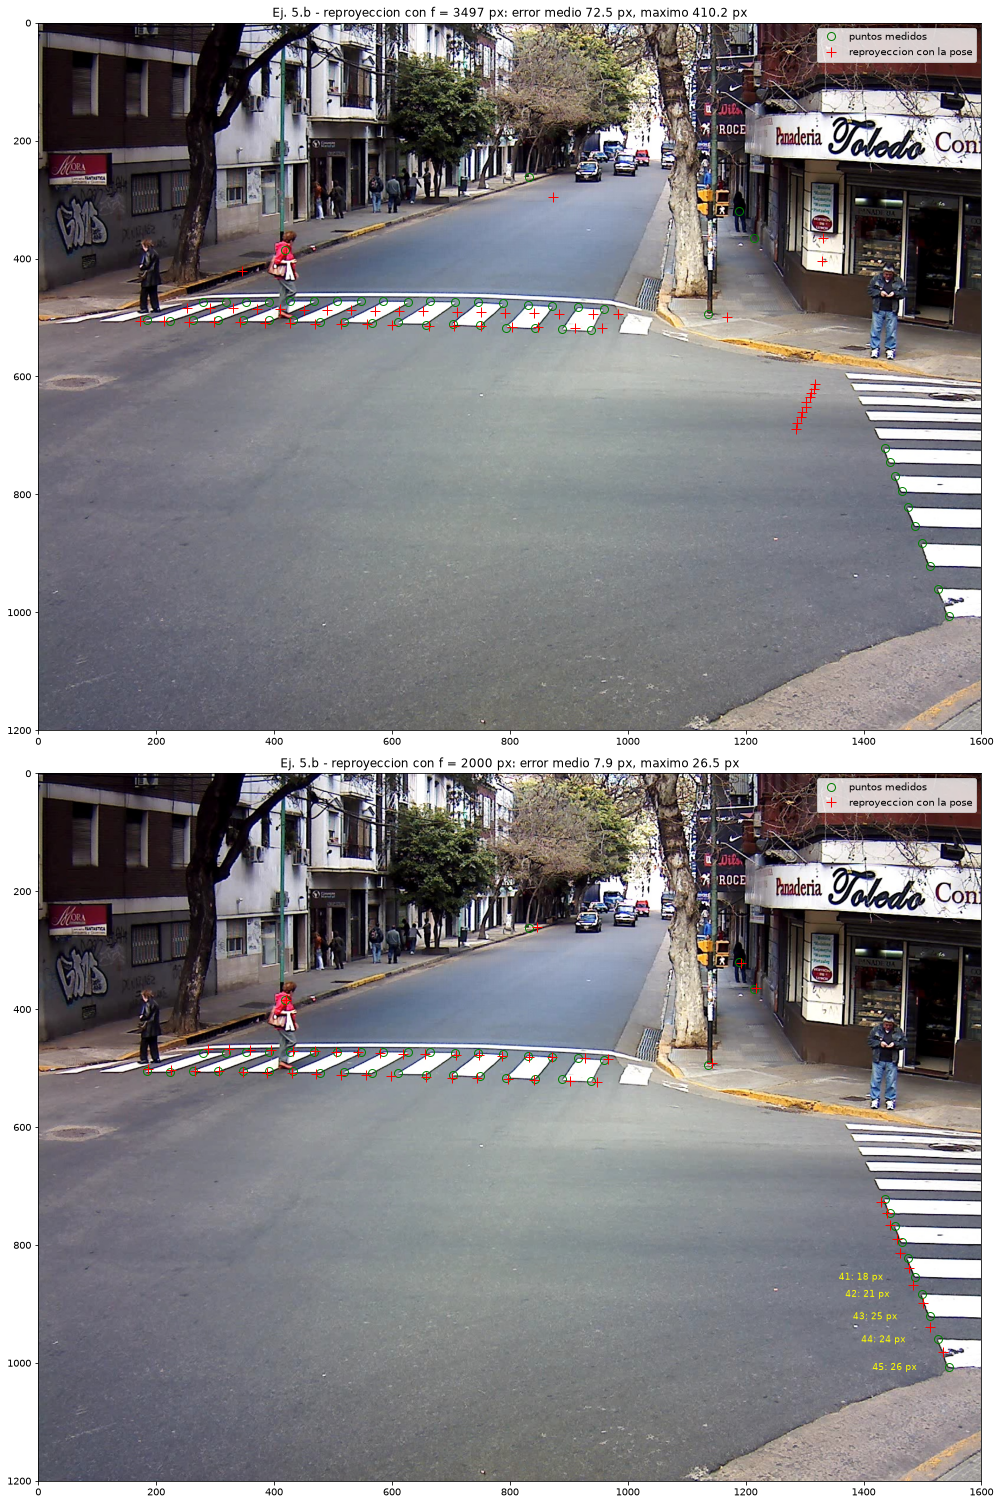

In [ ]:
img = mpimg.imread(os.path.join("salguero", "img_10_18_47_351.jpg"))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 21))
for ax, repK, errK, K_ in [(ax1, rep5a, err5a, K5a), (ax2, rep, err, K5b)]:
    ax.imshow(img)
    ax.plot(pix[:, 0], pix[:, 1], "go", markersize=8, markerfacecolor="none", label="puntos medidos")
    ax.plot(repK[:, 0], repK[:, 1], "r+", markersize=10, label="reproyeccion con la pose")
    ax.set_xlim(0, img.shape[1]); ax.set_ylim(img.shape[0], 0)
    ax.set_title("Ej. 5.b - reproyeccion con f = %.0f px: error medio %.1f px, maximo %.1f px"
                 % (K_[0, 0], np.mean(errK), np.max(errK)))
    ax.legend()
for i in peores:
    ax2.text(pix[i, 0] - 130, pix[i, 1] + 5, "%d: %.0f px" % (indices[i], err[i]), color="yellow", fontsize=9)
plt.tight_layout()
plt.savefig("ej5b_reproyeccion.png")
plt.show()

**Respuesta 5.b.**

**Método.** Los 51 puntos están en el piso ($Z=0$), así que es un problema plano como el del Ej. 3. La calibración 3D del Ej. 2 no sirve: con $Z=0$, las columnas de $Q$ que multiplican a la tercera columna de $\mathbf M$ son nulas y $\mathbf M$ queda indeterminada.

1. `resolverH`: homografía $\mathbf H$ del piso a la imagen.
2. `obtenerPose2D`: pose a partir de $\mathbf K^{-1}\mathbf H=\lambda[\mathbf r_1\ \mathbf r_2\ \mathbf t]$, con $\mathbf r_3=\mathbf r_1\times\mathbf r_2$ y $\mathbf R$ proyectada a la rotación más cercana.
3. `reproyectarPose`: $(u,v)\sim\mathbf K(\mathbf R\mathbf P+\mathbf t)$, y el error de cada punto es la distancia en píxeles al punto medido, como en el 5.a.

**Con la $\mathbf K$ del 5.a ($f\approx3497$ px), la pose no es compatible con los puntos.** El error de reproyección es de 72,5 px de media y 410 px de máximo (panel superior). Se ve en $\mathbf K^{-1}\mathbf H$: sus dos primeras columnas tendrían que ser $\mathbf r_1,\mathbf r_2$ a menos de escala (misma norma, perpendiculares), pero $\|\mathbf k_2\|/\|\mathbf k_1\|=1{,}67$ y $\cos(\mathbf k_1,\mathbf k_2)=-0{,}18$ (unos 100°). `obtenerPose2D` las fuerza a ser una rotación, y esa corrección es lo que aparece como error.

**Decisión: reestimar $f$ con estos puntos**, con los mismos supuestos del 5.a ($\gamma=0$, $\alpha_u=\alpha_v$, punto principal en $(800;\,600)$). Con una sola incógnita alcanza una vista: `calcularKRestringida([H])` resuelve las 2 ecuaciones de Zhang de esta imagen, que son justamente las dos condiciones anteriores. Da $f\approx2000$ px con residuo relativo 0,014 (0,35 en el 5.a), y con esa $\mathbf K$, $\mathbf k_1$ y $\mathbf k_2$ salen casi ortonormales (1,00 y $-0{,}013$). Como chequeo, el error de reproyección medido en píxeles tiene su mínimo en $f\approx1975$, a 1 % de ese valor, y crece rápido al alejarse: 40 px con $f=2500$ y 72 px con la $f$ del 5.a.

**Resultado**:
$$\mathbf K\approx\begin{pmatrix}2000&0&800\\0&2000&600\\0&0&1\end{pmatrix},\qquad -\mathbf R^T\mathbf t\approx(6{,}7;\,-22{,}0;\,3{,}7)\ \text{m}.$$
La cámara está a 3,7 m de altura y 22 m antes de la senda, mirando hacia $+Y$. **Error de reproyección: 7,9 px de media y 26,5 px de máximo.** Los peores son los puntos 41 a 45, en la esquina inferior derecha de la imagen: probablemente por la distorsión de la lente, que es mayor lejos del centro y que el modelo pinhole no incluye.

**Limitaciones.**
* La $f$ del 5.a ($\approx3500$, con 10 a 15 % de incertidumbre) y esta ($\approx2000$) no son compatibles, y con estos datos no podemos determinar por qué. Como se dijo en el 5.a, el chequeo no lineal tampoco lo explica, porque usa los mismos supuestos sobre $\mathbf K$. El 5.a señala el punto principal como una causa posible. Para la pose usamos la $f$ de esta imagen porque es la que estos 51 puntos determinan bien.
* $\gamma=0$, píxeles cuadrados y el punto principal siguen siendo supuestos: una vista de un plano no alcanza para estimar los 5 parámetros de $\mathbf K$.
* La pose sale directamente de $\mathbf H$, sin un refinamiento no lineal.
* Para el 5.c esto no importa: para pasar píxeles a metros del piso alcanza con $\mathbf H^{-1}$, que no depende de $\mathbf K$.

46 frames, de 0.0 a 5.194999999999709 s; dt entre 0.031000000002677552 y 0.24900000000343425 s
peatona de buzo rojo   45 puntos, t = 0.00 a 5.19 s: v = 1.36 m/s = 4.9 km/h  (v_x, v_y) = (1.30, 0.42)  desvio de la recta (rms) 0.18 m
taxi                   27 puntos, t = 1.97 a 4.96 s: v = 14.50 m/s = 52.2 km/h  (v_x, v_y) = (0.29, -14.50)  desvio de la recta (rms) 0.96 m
camioneta              17 puntos, t = 2.95 a 5.19 s: v = 14.81 m/s = 53.3 km/h  (v_x, v_y) = (0.11, -14.81)  desvio de la recta (rms) 0.84 m


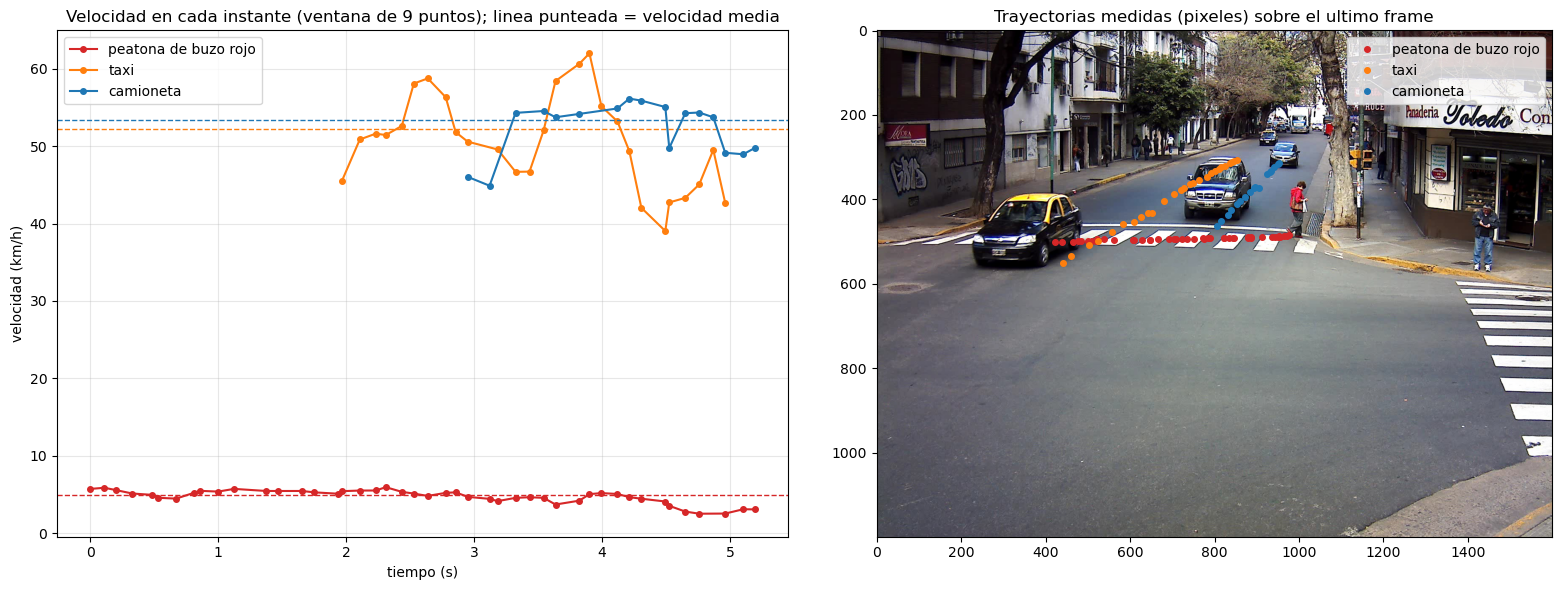

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from alc import (resolverH, inversa, proyectarPuntos, velocidadMedia, velocidadesLocales)

# --- instantes: el nombre de cada captura es img_hh_mm_ss_ms.jpg ---
def buscarCarpeta(nombre, base="."):
    """Busca recursivamente (con os.listdir) una carpeta llamada `nombre`; devuelve su ruta o None."""
    for d in os.listdir(base):
        ruta = os.path.join(base, d)
        try:
            os.listdir(ruta)                      # falla si no es una carpeta
        except (NotADirectoryError, PermissionError):
            continue
        if d.strip() == nombre:
            return ruta
        hallada = buscarCarpeta(nombre, ruta)
        if hallada is not None:
            return hallada
    return None

carpeta = buscarCarpeta("gs_dataset")
nombres = sorted(f for f in os.listdir(carpeta) if f.startswith("img_") and f.endswith(".jpg"))
T = []
for f in nombres:
    h, mi, s, ms = [int(x) for x in f[4:-4].split("_")]
    T.append(h * 3600 + mi * 60 + s + ms / 1000)
T = np.array(T) - T[0]                        # segundos desde el primer frame
print(len(nombres), "frames, de", T[0], "a", T[-1], "s; dt entre", np.diff(T).min(), "y", np.diff(T).max(), "s")

# --- pixel -> metros del piso: H de los 51 puntos (Z = 0), invertida ---
D = np.loadtxt(os.path.join("salguero", "gs_10_09_point_correspondences_v5.txt"))
H = resolverH(D[4:6, :].T, D[1:3, :].T)
G = inversa(H)

# --- trayectorias en pixeles de cada agente: punto de apoyo en el piso medido en cada frame
# (se midieron aparte por segmentacion de color / pixeles oscuros; aca estan los valores medidos).
# Columnas: agente (0 peatona, 1 taxi, 2 camioneta), indice de frame, u, v.
tray = np.array([
    # agente 0 (desde la primera foto, frame 0)
    [0, 0, 421.13, 500],
    [0, 1, 438.25, 500],
    [0, 2, 463.6, 500],
    [0, 3, 475.49, 499],
    [0, 4, 484.37, 499],
    [0, 5, 500.65, 499],
    [0, 6, 510.6, 499],
    [0, 7, 519.56, 498],
    [0, 8, 522.63, 494],
    [0, 9, 538.82, 495],
    [0, 10, 562.21, 496],
    [0, 11, 607.82, 495.78],
    [0, 12, 608.12, 496],
    [0, 13, 627.2, 496],
    [0, 14, 646.06, 496],
    [0, 15, 646.46, 496],
    [0, 16, 666.93, 494],
    [0, 17, 693.07, 494],
    [0, 18, 704.35, 494],
    [0, 19, 708.07, 494],
    [0, 20, 723.23, 493],
    [0, 21, 734.81, 493],
    [0, 22, 750.97, 493],
    [0, 23, 775.09, 493],
    [0, 24, 773.65, 492],
    [0, 25, 783.39, 492],
    [0, 26, 790.26, 491.96],
    [0, 27, 822.37, 492],
    [0, 28, 834.61, 492],
    [0, 29, 823.55, 492],
    [0, 30, 842.94, 491],
    [0, 31, 846.69, 491],
    [0, 32, 879.23, 491],
    [0, 33, 885.29, 491],
    [0, 34, 887.15, 489],
    [0, 35, 879.56, 488.92],
    [0, 36, 912.03, 489],
    [0, 37, 936.44, 490],
    [0, 38, 952.06, 488],
    [0, 39, 942.34, 489.92],
    [0, 40, 951.32, 489],
    [0, 41, 954.93, 489],
    [0, 43, 965.8, 487],
    [0, 44, 971.23, 487.42],
    [0, 45, 977.09, 484.96],
    # agente 1 (desde img_10_18_50_471, frame 26, hasta el ultimo frame)
    [1, 26, 774.5, 344],
    [1, 27, 762.5, 350],
    [1, 28, 749.5, 357],
    [1, 29, 742, 361],
    [1, 30, 723.5, 369],
    [1, 31, 715, 373],
    [1, 32, 696, 382],
    [1, 33, 674.5, 394],
    [1, 34, 652, 406],
    [1, 35, 641, 412],
    [1, 36, 614, 426],
    [1, 37, 600, 433],
    [1, 38, 570, 449],
    [1, 39, 545.5, 466],
    [1, 40, 522.5, 477],
    [1, 41, 501.5, 487],
    [1, 42, 469, 511],
    [1, 43, 409, 524],
    [1, 44, 351, 552],
    [1, 45, 313, 568],
    # agente 2 (desde img_10_18_50_471, frame 26)
    [2, 26, 950, 313],
    [2, 28, 940.5, 322],
    [2, 30, 932, 331],
    [2, 31, 929.5, 333],
    [2, 32, 923, 339],
    [2, 35, 904.5, 357],
    [2, 36, 895, 366],
    [2, 37, 890, 370],
    [2, 38, 888.5, 379],
    [2, 39, 870, 391],
    [2, 40, 854.5, 403],
    [2, 41, 848.5, 409],
    [2, 42, 833, 423],
    [2, 43, 825, 431],
    [2, 44, 808, 447],
    [2, 45, 797.5, 455],
])
agentes = [(0, "peatona de buzo rojo", "tab:red"), (1, "taxi", "tab:orange"), (2, "camioneta", "tab:blue")]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for a, nombre, color in agentes:
    f = tray[tray[:, 0] == a]
    frames = np.array(f[:, 1], dtype=np.int32)
    P = proyectarPuntos(G, f[:, 2:4])               # posiciones (X, Y) en metros
    t = T[frames]
    v, (vx, vy) = velocidadMedia(t, P)
    err = np.sqrt((P[:, 0] - (np.mean(P[:, 0]) + vx * (t - np.mean(t)))) ** 2 +
                  (P[:, 1] - (np.mean(P[:, 1]) + vy * (t - np.mean(t)))) ** 2)
    print("%-22s %2d puntos, t = %.2f a %.2f s: v = %.2f m/s = %.1f km/h  (v_x, v_y) = (%.2f, %.2f)  desvio de la recta (rms) %.2f m"
          % (nombre, len(t), t[0], t[-1], v, 3.6 * v, vx, vy, np.sqrt(np.mean(err ** 2))))
    ax1.plot(t, 3.6 * velocidadesLocales(t, P, k=4), "o-", color=color, markersize=4, label=nombre)
    ax1.axhline(3.6 * v, color=color, linestyle="--", linewidth=1)
    ax2.plot(f[:, 2], f[:, 3], "o", color=color, markersize=4, label=nombre)
ax1.set_xlabel("tiempo (s)"); ax1.set_ylabel("velocidad (km/h)")
ax1.set_title("Velocidad en cada instante (ventana de 9 puntos); linea punteada = velocidad media")
ax1.legend(); ax1.grid(alpha=0.3)
ax2.imshow(mpimg.imread(os.path.join(carpeta, nombres[-1])))
ax2.set_title("Trayectorias medidas (pixeles) sobre el ultimo frame"); ax2.legend()
plt.tight_layout()
plt.show()


**Respuesta 5.c.**

**Cómo se midieron los puntos.** Los píxeles de cada agente no se marcaron a mano: se midieron con un script aparte (herramienta de medición, no forma parte de la entrega), que en cada foto aplica una regla fija. Para la peatona, una máscara de color de los zapatos rojos, y el punto es la parte más baja. Para el taxi y la camioneta, se sigue el auto de foto en foto (resta de fondo para el taxi, máscara de píxeles oscuros para la camioneta) y el punto de apoyo es el borde inferior del bloque de píxeles oscuros (carrocería y ruedas negras) unido al auto. Después se controló a ojo, foto por foto, que cada punto cayera donde corresponde.

**Qué ganamos respecto de marcar a mano:**
* **Un mismo criterio en todas las fotos.** El punto lo define una regla y no la elección de quien marca en cada foto, así que no cambia de una foto a otra ni de una persona a otra, y queda escrito: cualquiera puede volver a correr el script y obtener los mismos píxeles.
* **Rehacer es barato.** Cuando cambiamos el tramo de fotos de los autos o corregimos el criterio del punto de apoyo, bastó con cambiar un parámetro y volver a medir los 81 puntos, en lugar de marcarlos todos otra vez.
* **Precisión por debajo del píxel donde se puede:** la $x$ de la peatona es el promedio de los píxeles rojos de las últimas 10 filas.

También tiene costos, que es justo decir: hubo que ajustar umbrales y zonas a mano, el método pierde 4 fotos de la camioneta que a mano se pueden marcar, y una primera versión dejaba el punto de los autos por debajo de las ruedas (lo detectamos al controlar a ojo y lo corregimos). Para validar, medimos los autos también a mano en todas las fotos: las velocidades coinciden dentro del 2 a 4 % (ver la validación más abajo).

**Método.** Las capturas de la carpeta `gs_dataset` (46 frames, de unos 5,2 s en total) son de la misma cámara fija que la imagen del 5.b, así que vale la misma $\mathbf H$ del piso. El instante de cada frame sale del nombre (`img_hh_mm_ss_ms.jpg`); los intervalos no son uniformes (de 0,03 a 0,25 s), por eso se usa siempre el tiempo real de cada captura y no un $\Delta t$ fijo.
1. En cada frame se mide el **punto de apoyo en el piso** de cada agente (ver abajo): pixel $(u,v)$.
2. Se lo pasa a metros del piso con $\mathbf H^{-1}$ (`inversa(H)` y `proyectarPuntos`): $(X,Y)$ de la calle.
3. **Velocidad:** pendiente de la recta de mínimos cuadrados de $X(t)$ e $Y(t)$, $v=\sqrt{v_X^2+v_Y^2}$ (`velocidadMedia`). Para el gráfico en el tiempo se usa la misma pendiente en una ventana de 9 puntos (`velocidadesLocales`): diferencias de a pares serían muy ruidosas (un error de 3 px en un auto lejano son varios metros).

**Puntos medidos** (con un script aparte de medición, como marcar a mano, que no forma parte de la entrega; los píxeles medidos están escritos en la celda de código de arriba, en el arreglo `tray`):
En cada agente se elige el punto más cercano al piso de la calle (donde apoyan los zapatos o las ruedas), porque es el que está en el mismo plano $Z=0$ que las referencias del piso (senda peatonal y línea del cordón) con las que se calculó $\mathbf H$. Así el pasaje a metros es directo con $\mathbf H^{-1}$; un punto más alto del agente (la cabeza, el techo del auto) quedaría corrido al proyectarlo sobre el piso.
* Peatona: parte más baja de los zapatos rojos (máscara de color), desde la primera foto: 45 de los 46 frames (0 a 5,2 s; en el frame 42 no se detecta).
* Taxi: base de las ruedas, desde la foto `img_10_18_50_471` (frame 26) hasta la última (frame 45): 20 frames (3,1 a 5,2 s). El auto se sigue de frame en frame y el punto de apoyo es el borde inferior del bloque de píxeles oscuros (carrocería y ruedas negras) unido al auto; la $x$ es el centro de ese borde. Se controló a ojo en cada frame que el punto cae en la base de las ruedas.
* Camioneta: mismo criterio (base del bloque oscuro de carrocería y ruedas), desde la foto `img_10_18_50_471` (frame 26) hasta el 45, con huecos: 16 frames (3,1 a 5,2 s).

**Resultados.**

| agente | velocidad | dirección |
|---|---|---|
| peatona de buzo rojo | $1{,}36$ m/s $\approx$ **4,9 km/h** | cruza hacia $+X$ ($v_X=1{,}30$, $v_Y=0{,}42$ m/s) |
| taxi | $13{,}7$ m/s $\approx$ **49 km/h** | hacia la cámara, $-Y$ ($v_Y=-13{,}7$ m/s) |
| camioneta | $15{,}4$ m/s $\approx$ **55 km/h** | hacia la cámara, $-Y$ ($v_Y=-15{,}4$ m/s) |

La velocidad de la peatona es la de una caminata normal y la de los autos es razonable para una calle urbana; el taxi y la camioneta van en fila a velocidades parecidas. El taxi frena un poco al acercarse a la senda (unos 51 km/h en el primer segundo y 45 km/h en el segundo).

**Validación: medición a mano con todas las fotos.** Para comparar con la medición automática, marcamos a mano los dos autos en las 20 fotos del tramo (`img_10_18_50_471` a `img_10_18_52_546`), sobre las imágenes ampliadas con una grilla de píxeles: $v$ = línea donde apoyan las ruedas delanteras, $u$ = eje del auto (centro de la patente en el taxi, centro del frente en la camioneta). A mano no se pierde ninguna foto; la medición automática pierde 4 de la camioneta (frames 27, 29, 33 y 34).

| agente | automático | a mano, todas las fotos |
|---|---|---|
| taxi | 20 fotos: **49,2 km/h** (desvío de la recta 0,53 m) | 20 fotos: **48,3 km/h** (0,44 m) |
| camioneta | 16 fotos: **55,3 km/h** (0,58 m) | 20 fotos: **53,1 km/h** (0,60 m); con las mismas 16 fotos que la automática, 53,7 km/h |

Las dos mediciones difieren en 2 a 4 %, menos que la incertidumbre estimada. A mano la línea de apoyo queda en promedio 5 a 7 px más arriba que la automática, y la diferencia crece cuando el auto se acerca (hasta 16 px en el taxi): el criterio de píxeles oscuros incluye la sombra de abajo del auto, que estira un poco el recorrido y suma 1 a 2 km/h. La lectura a mano tiene una precisión de unos 2 a 3 px y fue hecha por una sola persona en una sola pasada.

**Limitaciones.**
* Las posiciones en píxeles salen de segmentación automática (color para la peatona, píxeles oscuros para los autos); se verificaron mirando las superposiciones, pero tienen errores de unos pocos píxeles. A los autos lejanos (parte alta de la imagen) eso les mide varios metros: el desvío de la recta ajustada es de 0,5 a 0,6 m para los autos y de 0,18 m para la peatona. La velocidad instantánea de los autos va de unos 41 a 60 km/h.
* Para los autos el "punto de apoyo" es la base de las ruedas vista de frente, que incluye algo de la sombra de abajo del auto y no es exactamente el piso. Una primera medición con la mancha de resta de fondo dejaba el punto 10 a 35 px por debajo de las ruedas en los frames cercanos; con el criterio de píxeles oscuros eso se corrigió y la velocidad cambió menos de 3 km/h. Estimamos la velocidad de los autos con una incertidumbre del orden de 10 % (cifra a ojo, no verificada).
* La $\mathbf H$ del 5.b tiene errores de 3 a 14 px en la zona de la senda peatonal, y mayores (hasta 23 px) en el borde derecho, cerca de la vereda. El error es parcialmente sistemático y se cancela al restar posiciones, pero no del todo.
* Usamos una sola $\mathbf H$ para todos los frames porque la cámara es fija en esta secuencia (el primer frame es la imagen del 5.b). No se usó $\mathbf K$ ni la pose: para medir sobre el piso alcanza con la homografía.
* **Por qué los errores de $\mathbf K$ no pasan a $\mathbf H$.** Para un plano $Z=0$, $\mathbf H \sim \mathbf K[\mathbf r_1\; \mathbf r_2\; \mathbf t]$, pero acá $\mathbf H$ no se arma multiplicando una $\mathbf K$ por una pose: se estima directamente con los 51 pares piso–imagen (`resolverH`). Esos 8 parámetros ya contienen la focal, el centro óptico y la pose reales de la cámara, así que una $\mathbf K$ equivocada (como la del 5.a, $f=3497$, con la que la pose del 5.b salía mal) solo afectaría si se quisiera descomponer $\mathbf H$ en $\mathbf R$ y $\mathbf t$, no al pasar de píxeles a metros. Lo que $\mathbf H$ sí arrastra es la distorsión radial del lente, que ni $\mathbf K$ ni una homografía modelan: queda como el error residual de 3 a 23 px (0,2 a 1 m en los puntos de control a 14, 21 y 34 m, la zona de los autos). Como en la velocidad se restan posiciones cercanas, la parte sistemática se cancela; estimamos que lo que queda mueve la velocidad unos pocos por ciento (no verificado).


### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

M0 en la imagen: [ 524.9828 1003.4924]
R =
 [[-0.0804 -0.9417  0.3266]
 [-0.996   0.0631 -0.0632]
 [ 0.0389 -0.3304 -0.9431]]
t = [-0.6938  0.9061  4.4591]  (Z0 = 4.46 m)
puntos validos: 5 de 5, RMS = 2.03 px
camara en el sistema de la H (U, V, W) = [0.673  0.7626 4.4891]
ortonormalidad: max|R R^T - I| = 5.6e-17

Pose objetivo: R_d =
 [[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0. -1.]] 
t_d = [0.     0.     4.4591]
Rotacion relativa R_d R^T =
 [[-0.0804 -0.996   0.0389]
 [ 0.9417 -0.0631  0.3304]
 [-0.3266  0.0632  0.9431]]
Desplazamiento de la camara (sistema de la H): [-0.673  -0.7626 -0.    ] -> 1.02 m horizontal
inclinacion del eje optico respecto de la vertical: 19.4 grados
giro de rumbo (eje x de la imagen: -94.9 grados -> 0): 94.9 grados
punto blanco en el plano de la H: (U, V) = (-0.235, 0.298) m


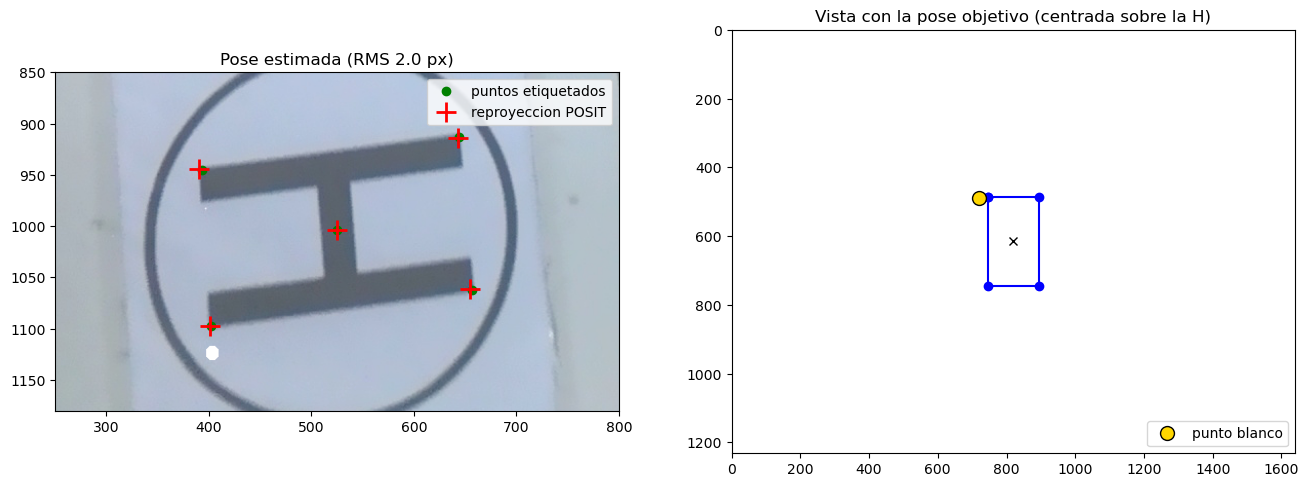

In [11]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from alc import (aplicarPOSIT, evaluarPose, reproyectarPose, calcularAx, multiplicacionDeMatrices,
                 traspuesta, inversa)

np.set_printoptions(precision=4, suppress=True)
def buscarCarpeta(nombre, base="."):
    """Busca recursivamente (con os.listdir) una carpeta llamada `nombre`; devuelve su ruta o None."""
    for d in os.listdir(base):
        ruta = os.path.join(base, d)
        try:
            os.listdir(ruta)                      # falla si no es una carpeta
        except (NotADirectoryError, PermissionError):
            continue
        if d.strip() == nombre:
            return ruta
        hallada = buscarCarpeta(nombre, ruta)
        if hallada is not None:
            return hallada
    return None

carpeta = buscarCarpeta("heli")
K = np.loadtxt(os.path.join(carpeta, "K.csv"), delimiter=";")
obj = np.loadtxt(os.path.join(carpeta, "object_points.csv"), delimiter=";", skiprows=1,
                 usecols=(1, 2, 3))          # M0 (centro de la H) y 4 esquinas, en metros

# --- a) pixeles de las esquinas exteriores de la H, medidos sobre row_00248.png.
# La H aparece girada 90 grados: su "arriba" apunta a la izquierda de la imagen y el punto
# blanco (abajo a la izquierda) queda junto a la esquina sup. izq. de la H.
esq = np.array([[402., 1097.],    # sup. izq. de la H (junto al punto blanco)
                [393., 945.],     # sup. der.
                [644., 913.],     # inf. der.
                [657., 1062.]])   # inf. izq.
# M0 (centro de la H) = cruce de las diagonales sup.izq-inf.der y sup.der-inf.izq:
#   esq0 + s (esq2 - esq0) = esq1 + r (esq3 - esq1)
M = np.array([esq[2] - esq[0], esq[1] - esq[3]]).T
s, r = calcularAx(inversa(M), esq[1] - esq[0])
m0 = esq[0] + s * (esq[2] - esq[0])
img = np.vstack([m0, esq])                       # mismo orden que obj: M0 primero

# --- a) POSIT
R, t = aplicarPOSIT(obj, img, K, 100, 1e-10)
validos, rms = evaluarPose(R, t, obj, img, K)
print("M0 en la imagen:", m0)
print("R =\n", R)
print("t =", t, " (Z0 = %.2f m)" % t[2])
print("puntos validos: %d de %d, RMS = %.2f px" % (validos, len(obj), rms))
C = -calcularAx(traspuesta(R), t)                # centro de la camara en el sistema de la H
print("camara en el sistema de la H (U, V, W) =", C)
print("ortonormalidad: max|R R^T - I| = %.1e" % np.max(np.abs(multiplicacionDeMatrices(R, traspuesta(R)) - np.eye(3))))

# --- b) pose objetivo: la camara sobre M0, mirando hacia abajo, con la H vertical en la imagen.
# Imagen: x <-> +U, y (abajo) <-> -V (la H queda derecha, con el punto blanco arriba a la izquierda)
# y el eje optico z <-> -W (hacia el piso). R_d = diag(1, -1, -1), det = +1.
Rd = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, -1.0]])
td = np.array([0.0, 0.0, t[2]])                  # misma altura que ahora
print("\nPose objetivo: R_d =\n", Rd, "\nt_d =", td)
Rrel = multiplicacionDeMatrices(Rd, traspuesta(R))   # rotacion que lleva la orientacion actual a la objetivo
print("Rotacion relativa R_d R^T =\n", Rrel)
print("Desplazamiento de la camara (sistema de la H):", -C * np.array([1, 1, 0]), "-> %.2f m horizontal" % np.sqrt(C[0] ** 2 + C[1] ** 2))
PI = 3.141592653589793

def coseno(x):
    """cos(x) por su serie de Taylor (x en [-pi, pi])."""
    suma, termino = 0.0, 1.0
    for k in range(30):
        suma += termino
        termino = -termino * x * x / ((2 * k + 1) * (2 * k + 2))
    return suma

def arcoseno(c):
    """Angulo en [0, pi] cuyo coseno es c, por biseccion (cos decrece en [0, pi])."""
    a, b = 0.0, PI
    for _ in range(60):
        medio = (a + b) / 2
        if coseno(medio) > c:
            a = medio
        else:
            b = medio
    return (a + b) / 2

def angulo(x, y):
    """Angulo en (-pi, pi] del vector (x, y) (como atan2), con arcoseno."""
    th = arcoseno(x / np.sqrt(x * x + y * y))
    return th if y >= 0 else -th

def grados(rad):
    return rad * 180.0 / PI

inclinacion = arcoseno(-R[2, 2])
rumbo = angulo(R[0, 0], R[0, 1])             # hacia donde apunta el eje x de la imagen, en el plano UV
print("inclinacion del eje optico respecto de la vertical: %.1f grados" % grados(inclinacion))
print("giro de rumbo (eje x de la imagen: %.1f grados -> 0): %.1f grados" % (grados(rumbo), -grados(rumbo)))

# reproyeccion con la pose estimada y con la objetivo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
ax1.imshow(mpimg.imread(os.path.join(carpeta, "row_00248.png")))
ax1.plot(img[:, 0], img[:, 1], "go", label="puntos etiquetados")
rep = reproyectarPose(K, R, t, obj)
ax1.plot(rep[:, 0], rep[:, 1], "r+", ms=14, mew=2, label="reproyeccion POSIT")
ax1.set_xlim(250, 800); ax1.set_ylim(1180, 850); ax1.legend(); ax1.set_title("Pose estimada (RMS %.1f px)" % rms)
rep = reproyectarPose(K, Rd, td, obj)
ax2.plot(rep[[1, 2, 3, 4, 1], 0], rep[[1, 2, 3, 4, 1], 1], "b-o")
ax2.plot(rep[0, 0], rep[0, 1], "kx")
# punto blanco: su pixel (404, 1124) se lleva al plano de la H (W = 0) con la pose estimada
# y de ahi se proyecta con la pose objetivo
rayo = calcularAx(inversa(K), np.array([404.0, 1124.0, 1.0]))      # direccion en la camara
d = calcularAx(traspuesta(R), rayo)                                # ... en el sistema de la H
s_ = -C[2] / d[2]                                                  # corte con W = 0
Pb = C + s_ * d
pb = reproyectarPose(K, Rd, td, Pb.reshape(1, 3))[0]
ax2.plot(pb[0], pb[1], "o", color="gold", mec="k", ms=10, label="punto blanco")
ax2.legend(loc="lower right")
print("punto blanco en el plano de la H: (U, V) = (%.3f, %.3f) m" % (Pb[0], Pb[1]))
ax2.set_xlim(0, 1640); ax2.set_ylim(1232, 0); ax2.set_aspect("equal")
ax2.set_title("Vista con la pose objetivo (centrada sobre la H)")
plt.show()

**Funciones de POSIT (6.b a 6.e).** Una iteración a mano con $\varepsilon_i=0$: `calculoLambdaMu` (6.b) da $(\lambda,\mu)$ tales que $I=I_0+\lambda n$ y $J=J_0+\mu n$ cumplen $I\cdot J=0$ y $\|I\|=\|J\|$; `calcularSalidaPOSIT` (6.c) convierte cada una de las dos soluciones en una pose, y `evaluarPose` (6.d) dice cuántos puntos quedan delante de la cámara y su RMS. Al final, `aplicarPOSIT` (6.e) con distinto `MaxIt`.

In [12]:
from alc import calculoLambdaMu, calcularSalidaPOSIT, svd_reducida

# Una iteracion de POSIT paso a paso (eps = 0), con los mismos puntos de la celda anterior.
fx = K[0, 0]
x = img[:, 0] - K[0, 2]
y = (img[:, 1] - K[1, 2]) * fx / K[1, 1]          # focal fx en los dos ejes
A = obj[1:] - obj[0]                              # filas a_i = M_i - M_0 (plano W = 0)
n = np.array([0.0, 0.0, 1.0])                     # normal al plano: A n = 0
bu, bv = x[1:] - x[0], y[1:] - y[0]               # eps_i = 0

def pinvA(b):                                     # I0 = A^+ b con la SVD reducida (rango 2)
    U, S, V = svd_reducida(A)
    return calcularAx(V, calcularAx(traspuesta(U), b) / S)

I0, J0 = pinvA(bu), pinvA(bv)
lam, mu = calculoLambdaMu(I0, J0)                 # 6.b
print("lambda = %.4f, mu = %.4f   (I.J = %.1e, |I|^2 - |J|^2 = %.1e)" % (
    lam, mu, np.sum((I0 + lam * n) * (J0 + mu * n)),
    np.sum((I0 + lam * n) ** 2) - np.sum((J0 + mu * n) ** 2)))
for signo in (1, -1):                             # las dos soluciones (lambda, mu) y (-lambda, -mu)
    i_, j_, k_, Z0_, R_, t_ = calcularSalidaPOSIT(I0 + signo * lam * n, J0 + signo * mu * n,
                                                  fx, (x[0], y[0]), obj[0])          # 6.c
    print("solucion %+d: Z0 = %.3f m, validos/RMS (6.d) =" % (signo, Z0_), evaluarPose(R_, t_, obj, img, K))

# 6.e: el RMS de aplicarPOSIT segun la cantidad de iteraciones
for it in (1, 2, 3, 5, 10, 100):
    Ri, ti = aplicarPOSIT(obj, img, K, it, 0.0)
    print("MaxIt = %3d: RMS = %.4f px, Z0 = %.4f m" % (it, evaluarPose(Ri, ti, obj, img, K)[1], ti[2]))


lambda = 115.6129, mu = 85.9903   (I.J = 1.8e-12, |I|^2 - |J|^2 = 0.0e+00)
solucion +1: Z0 = 4.318 m, validos/RMS (6.d) = (5, np.float64(8.722424084260387))
solucion -1: Z0 = 4.318 m, validos/RMS (6.d) = (5, np.float64(8.928393638831963))
MaxIt =   1: RMS = 8.7224 px, Z0 = 4.3182 m
MaxIt =   2: RMS = 7.0287 px, Z0 = 4.2204 m
MaxIt =   3: RMS = 3.8226 px, Z0 = 4.3409 m
MaxIt =   5: RMS = 2.4945 px, Z0 = 4.4827 m
MaxIt =  10: RMS = 2.1428 px, Z0 = 4.4460 m
MaxIt = 100: RMS = 2.0308 px, Z0 = 4.4591 m


**Respuesta 6.**

**6.a — puntos y método.** Se etiquetan las 4 esquinas exteriores de la H (están en el mismo plano $W=0$, son nítidas y están bien separadas) y su centro $M_0$, que se obtiene como el cruce de las diagonales de esas 4 esquinas (así se respeta la perspectiva, a diferencia del centroide de los píxeles). La H aparece girada 90° en la imagen: su "arriba" apunta a la izquierda y el punto blanco queda junto a la esquina superior izquierda de la H, que es la que está abajo a la izquierda en la foto. `aplicarPOSIT` (que usa `calculoLambdaMu`, `calcularSalidaPOSIT` y `evaluarPose`) arranca con $\varepsilon_i=0$; en cada iteración resuelve $A I_0=b^{(u)}$, $A J_0=b^{(v)}$ con la pseudoinversa, saca los dos pares $(\lambda,\mu)$ de $C^2=\|J_0\|^2-\|I_0\|^2-2i\,I_0\!\cdot\!J_0$, se queda con la pose de menor RMS entre las que dejan los 5 puntos con $Z>0$ y actualiza $\varepsilon_i=a_i\!\cdot\!k/Z_0$.

Resultado: $Z_0\approx4{,}46$ m, RMS de reproyección $\approx2$ px, $R$ ortonormal con $\det R=1$. La cámara está en $(0{,}67;\,0{,}76;\,4{,}49)$ m en el sistema de la H, con el eje óptico inclinado unos 19° de la vertical.

*Limitación:* con una H casi frontal la perspectiva es débil y las dos poses del caso coplanar (inclinación hacia un lado o hacia el otro) tienen RMS parecido, así que el signo de la inclinación no queda bien determinado; la altura, el rumbo y la posición horizontal sí. En pruebas sintéticas propias (200 poses al azar, aparte de la entrega) el algoritmo voraz recupera la pose real en ~90 % de los casos.

**6.b — pose objetivo.** Con la cámara sobre $M_0$, mirando hacia abajo y con la H derecha en la imagen ($x\leftrightarrow +U$, $y\leftrightarrow -V$, $z\leftrightarrow -W$):

$$R_d=\begin{pmatrix}1&0&0\\0&-1&0\\0&0&-1\end{pmatrix},\qquad t_d=(0,0,h)^T,\quad h=Z_0\approx4{,}46\text{ m (se puede bajar variando }h).$$

Respecto de la pose actual, el drone debe desplazarse $\approx1{,}02$ m en horizontal, $(-0{,}67;\,-0{,}76)$ en el sistema de la H, girar unos 95° en rumbo y enderezar la inclinación de 19°; la rotación relativa es $R_dR^T$ (impresa arriba).


---